# 129 · Why didn't these runs beat their baselines?
Nine src9 transformer3 runs in three groups, each compared with its matching baseline on paired per-sample iou08 (eager eval outputs only):
- **A · input norm:** zlaser, zlaser-log, zfreq vs base300-v1-reeval@300. zfreq@200 is compared with a new eager re-eval of base300-v1@200.
- **B · readouts:** pool / cls / query vs drop30-v1-reeval@300.
- **C · tokenizer / arch:** overlap32, tokmlp, nolaserattn vs drop30-v1-reeval@300.

**Short answer:**
- Nothing beats its baseline on pooled ID or OOD.
- The readouts (B) fail badly and for a structural reason: no slot identity, so they snap to object-position priors.
- zlaser (A) overfits and breaks unseen speakers.
- overlap and tokmlp (C) change a tokenizer that never moves from its random init.
- nolaserattn is a tie at 18 % fewer params.
- Two changes, zfreq and nolaserattn, each robustly help **cardboard unseen-position**. That is the only combination lead worth a run.

The verdict table is at the end. The data caveat (compile eval bug) is handled throughout: the baselines are the eager `-reeval` dirs, every other run started after the fix, and the logged curves of the original baselines are marked as biased.

In [1]:
import os, sys, re, json, io, contextlib
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from callbacks import EvalSummary
from score import truth
plt.rcParams.update({"font.size": 15, "axes.titlesize": 17, "axes.labelsize": 16, "legend.fontsize": 13, "xtick.labelsize": 13, "ytick.labelsize": 14})
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
CACHE = Path("/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/4f4d6cce-0580-4e8f-a7d6-b4086bb83fa1/scratchpad/nb129/cache"); CACHE.mkdir(parents=True, exist_ok=True)
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
ID, OOD = list(EvalSummary.ID), list(EvalSummary.OOD)  # pooled ID = id + multiple, OOD = rotated, cylinder, unseen-object/-speaker/-laser, lid (same as the logged metrics)
BOXES = ["gastro", "plastic", "cardboard"]
BOXC = {"gastro": "#3B6FB6", "plastic": "#E07B39", "cardboard": "#7A9E4E"}
THR, K5 = 0.08, np.ones((5, 5), bool)

# (run, epoch of the saved eval outputs). Baselines = eager CPU re-evals of the final checkpoint, saved as ep0000.
BASE300, DROP30, BASE300_200 = ("base300-v1-reeval", 0), ("drop30-v1-reeval", 0), ("base300-v1-reeval-ep200", 0)
GROUPS = {"A": dict(name="input norm", base=BASE300, runs=[("zlaser-v1", 300), ("zlaser-log-v1", 300), ("zfreq-v1", 200)]),
          "B": dict(name="readouts", base=DROP30, runs=[("pool-abspos-m-v1", 300), ("cls-abspos-m-v1", 300), ("query-abspos-m-v1", 300)]),
          "C": dict(name="tokenizer / arch", base=DROP30, runs=[("overlap32-d30-v1", 300), ("tokmlp-d30-v1", 300), ("nolaserattn-d30-v1", 300)])}
def tag(r): return f"{r[0]}@{r[1] or {'base300-v1-reeval': 300, 'drop30-v1-reeval': 300, 'base300-v1-reeval-ep200': 200}[r[0]]}"

def band(m): return m & ~ndimage.binary_erosion(m, K5, border_value=0)  # 2 px inner band, = utils.biou

def score(p, y):
    """p (64,64) probabilities, y bool truth -> per-sample metrics at THR"""
    b = p > THR
    bb, by = band(b), band(y)
    lab, n = ndimage.label(y)
    cov = [(b & (lab == k)).sum() / (lab == k).sum() for k in range(1, n + 1)]
    far = ndimage.distance_transform_edt(~y) > 3
    return dict(iou=(b & y).sum() / max((b | y).sum(), 1), biou=(bb & by).sum() / max((bb | by).sum(), 1), area_p=b.sum(), area_t=y.sum(), n_obj=n,
                obj_hit=np.mean([c > 0 for c in cov]), obj_cov50=np.mean([c >= 0.5 for c in cov]), min_cov=min(cov),
                soft_frac=((p > THR) & (p < 0.92)).sum() / max(b.sum(), 1), extra_frac=(b & far).sum() / max(b.sum(), 1))

def per_sample(run, ep, part="eval"):
    """one row per scored sample of runs/<run>/outputs_history/<part> at epoch ep (cached)"""
    f = CACHE / f"{run}_ep{ep:04d}_{part}.pkl"
    if f.exists(): return pd.read_pickle(f)
    rows, seen = [], set()
    pat = f"eval/*/*/ep{ep:04d}-ba*.pt" if part == "eval" else f"train/ep{ep:04d}-ba*.pt"
    for pt in sorted((ROOT / "runs" / run / "outputs_history").glob(pat)):
        d = torch.load(pt, weights_only=False, map_location="cpu")
        P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            k = (info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i]))
            if k in seen: continue
            seen.add(k)
            y = truth(*k, 64, 64) > 0.5
            if not y.any(): continue
            box, split = (pt.parent.parent.name, pt.parent.name) if part == "eval" else (k[0], "train")
            rows.append(dict(box=box, split=split, cat=CAT.get((box, split), "train"), experiment=k[0], sample_id=k[1], position_id=k[2], speaker=k[3], **score(P[i], y)))
    df = pd.DataFrame(rows); df.to_pickle(f)
    return df
print("ok")

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


ok


## 0 · Do the baselines match? (args.json)
This table lists every flag that differs between any of the runs, the two baselines and the original training runs. The baselines (`*-reeval`) are eager CPU re-evals of each final checkpoint. `None` means the flag did not exist yet, so it takes today's default. The `-reeval` args.json files say drop .2 for both baselines. Only the arch flags matter for rebuilding the model, and dropout is off at eval, so this has no effect. The training-time values are in the original `base300-v1` / `drop30-v1` columns.

In [2]:
ARGRUNS = ["base300-v1", "zlaser-v1", "zlaser-log-v1", "zfreq-v1", "drop30-v1", "pool-abspos-m-v1", "cls-abspos-m-v1", "query-abspos-m-v1",
           "overlap32-d30-v1", "tokmlp-d30-v1", "nolaserattn-d30-v1"]
DEFAULT = dict(abspos=0, band_overlap=0, drop_rescale=0, freeze_readout=0, gan_w=0.0, log_mag=0, n_queries=16, norm="sample", query_layers=1, tokenizer="linear")  # flags added after base300-v1
A = {r: DEFAULT | {k: v for k, v in json.load(open(ROOT / f"runs/{r}/args.json")).items() if v is not None} for r in ARGRUNS}
SKIP = {"run_name", "wandb", "checkpoint_path", "eval_only", "debug_nan", "compile"}
keys = [k for k in sorted(set().union(*A.values())) if k not in SKIP and len({str(a.get(k)) for a in A.values()}) > 1]
ARGS = pd.DataFrame({r: {k: A[r].get(k) for k in keys} for r in ARGRUNS})
print("flags that differ (missing flags filled with today's default; every training run used --compile 1, whose eval bug was fixed before all non-baseline runs started)")
display(ARGS)
for g, G in GROUPS.items():
    b = {"base300-v1-reeval": "base300-v1", "drop30-v1-reeval": "drop30-v1"}[G["base"][0]]
    for r, _ in G["runs"]:
        print(f"{g} {r:20s} vs {b}: " + ", ".join(f"{k} {A[b].get(k)} -> {A[r].get(k)}" for k in keys if str(A[b].get(k)) != str(A[r].get(k))))

flags that differ (missing flags filled with today's default; every training run used --compile 1, whose eval bug was fixed before all non-baseline runs started)


,base300-v1,zlaser-v1,zlaser-log-v1,zfreq-v1,drop30-v1,pool-abspos-m-v1,cls-abspos-m-v1,query-abspos-m-v1,overlap32-d30-v1,tokmlp-d30-v1,nolaserattn-d30-v1
abspos,0,0,0,0,0,1,1,1,0,0,0
band_drop,0.2,0.2,0.2,0.2,0.3,0.3,0.3,0.3,0.3,0.3,0.3
band_overlap,0,0,0,0,0,0,0,0,32,0,0
d,256,256,256,256,256,400,400,336,256,256,256
heads,8,8,8,8,8,10,10,7,8,8,8
laser_drop,0.2,0.2,0.2,0.2,0.3,0.3,0.3,0.3,0.3,0.3,0.3
laser_layers,8,8,8,8,8,8,8,8,8,8,0
log_mag,0,0,1,0,0,0,0,0,0,0,0
microbatch,128,128,128,128,128,64,64,64,128,128,128
norm,sample,laser,laser,freq,sample,sample,sample,sample,sample,sample,sample


A zlaser-v1            vs base300-v1: norm sample -> laser
A zlaser-log-v1        vs base300-v1: log_mag 0 -> 1, norm sample -> laser
A zfreq-v1             vs base300-v1: norm sample -> freq
B pool-abspos-m-v1     vs drop30-v1: abspos 0 -> 1, d 256 -> 400, heads 8 -> 10, microbatch 128 -> 64, readout per -> pool
B cls-abspos-m-v1      vs drop30-v1: abspos 0 -> 1, d 256 -> 400, heads 8 -> 10, microbatch 128 -> 64, readout per -> cls
B query-abspos-m-v1    vs drop30-v1: abspos 0 -> 1, d 256 -> 336, heads 8 -> 7, microbatch 128 -> 64, readout per -> query
C overlap32-d30-v1     vs drop30-v1: band_overlap 0 -> 32
C tokmlp-d30-v1        vs drop30-v1: tokenizer linear -> mlp
C nolaserattn-d30-v1   vs drop30-v1: laser_layers 8 -> 0


## 1 · Per-sample scores from the saved predictions
Every eval sample of every run is re-scored from `outputs_history/eval/<box>/<split>/ep<E>-*.pt` against the true mask (`score.truth`, > .5) at p > .08. The metrics are:
- `iou` = iou08;
- `biou` = boundary IoU of the 2 px inner bands (same as `utils.biou`);
- area ratio = pred px / true px;
- `obj_hit` = fraction of true objects (connected components) with ≥ 1 predicted px, and `obj_cov50` = fraction ≥ 50 % covered;
- `soft_frac` = fraction of the predicted px with .08 < p < .92 (mushy edges);
- `extra_frac` = fraction of the predicted px > 3 px away from any object.

A **miss** is a sample with iou08 < .1. Pooled ID / OOD are per-sample means over the ID (id + multiple) / OOD categories, exactly like the logged `metrics/eval/{id,ood}/iou08`. The check below shows they reproduce the logged numbers.

An extra baseline, `base300-v1-reeval-ep200`, was made for this notebook. It is an eager CPU re-eval of `runs/base300-v1/checkpoints/ep200-ba2000-rank0.pt`, because zfreq-v1 only reached ep200, and comparing an ep200 model with an ep300 baseline is unfair.

In [3]:
ALL = [BASE300, BASE300_200, DROP30] + [r for G in GROUPS.values() for r in G["runs"]]
EV = {r: per_sample(*r) for r in ALL}
for r in [("zlaser-v1", 250), ("zlaser-log-v1", 250), ("zfreq-v1", 150), ("pool-abspos-m-v1", 250), ("cls-abspos-m-v1", 250), ("query-abspos-m-v1", 250),
          ("overlap32-d30-v1", 250), ("tokmlp-d30-v1", 250), ("nolaserattn-d30-v1", 250), ("zlaser-v1", 100), ("zlaser-v1", 50), ("zlaser-log-v1", 100), ("zfreq-v1", 100)]:
    EV[r] = per_sample(*r)
TR = {r: per_sample(*r, part="train") for r in [BASE300, DROP30] + [(n, 300) for G in GROUPS.values() for n, e in G["runs"] if e == 300]}

PAT = re.compile(r"^\[metric\]\[batch=(\d+)\]: (\S+): ([-\d.eE+naif]+)")
def parse(run):
    return pd.DataFrame([(int(m[1]), m[2], float(m[3])) for l in open(ROOT / f"runs/{run}/logs-rank0.txt") if (m := PAT.match(l))], columns=["batch", "key", "v"])
LOG = {r: parse(r) for r in ["base300-v1", "drop30-v1"] + [n for G in GROUPS.values() for n, _ in G["runs"]]}
def logged(run, key, batch): s = LOG[run]; s = s[(s.key == key) & (s.batch == batch)].v; return s.iloc[0] if len(s) else np.nan

def pooled(df): return pd.Series({"ID": df[df.cat.isin(ID)].iou.mean(), "OOD": df[df.cat.isin(OOD)].iou.mean()})
rows = []
for r in ALL:
    p = pooled(EV[r]); src = r[0].replace("-reeval-ep200", "").replace("-reeval", "")
    b = 10 * (r[1] or (200 if "ep200" in r[0] else 300))
    rows.append(dict(run=tag(r), ID=p.ID, OOD=p.OOD, logged_ID=logged(src, "metrics/eval/id/iou08", b), logged_OOD=logged(src, "metrics/eval/ood/iou08", b),
                     note="logged = compiled (buggy) eval" if "reeval" in r[0] else "logged = eager (post-fix)"))
POOLED = pd.DataFrame(rows).set_index("run")
print("pooled iou08 from the saved outputs vs the logged value at the same batch")
POOLED.round(4)

pooled iou08 from the saved outputs vs the logged value at the same batch


,ID,OOD,logged_ID,logged_OOD,note
run,,,,,
base300-v1-reeval@300,0.6800,0.3848,0.6669,0.3791,logged = compiled (buggy) eval
base300-v1-reeval-ep200@200,0.6714,0.3868,0.6579,0.3811,logged = compiled (buggy) eval
drop30-v1-reeval@300,0.6713,0.3855,0.6602,0.3790,logged = compiled (buggy) eval
zlaser-v1@300,0.6634,0.3606,0.6634,0.3606,logged = eager (post-fix)
zlaser-log-v1@300,0.6595,0.3569,0.6595,0.3569,logged = eager (post-fix)
zfreq-v1@200,0.6586,0.3771,0.6586,0.3771,logged = eager (post-fix)
pool-abspos-m-v1@300,0.5112,0.3147,0.5112,0.3147,logged = eager (post-fix)
cls-abspos-m-v1@300,0.5287,0.3146,0.5287,0.3146,logged = eager (post-fix)
query-abspos-m-v1@300,0.4994,0.3096,0.4994,0.3096,logged = eager (post-fix)


## 2 · Noise scale: how big must a Δ be to count?
**There are no seed repeats** of any transformer3 config, because every run uses seed 42. A search of all `runs/*/args.json` found no two training runs with the same config, so true seed noise cannot be measured here. The proxies below are used instead.

- **Sample noise** comes from a paired bootstrap. Both runs are scored on the same eval samples, and the bootstrap resamples **positions** rather than samples. Each position is recorded with 1–4 speakers, so those samples are correlated. The position-cluster CI is wider than the naive one and is used everywhere below.
- **Late-training jitter**: Δ between a run's own ep250 and ep300 outputs. The LR is almost annealed by then, so this is a lower bound on checkpoint noise.
- **Nearest-neighbour config**: base300-v1 vs drop30-v1 (drop .2 vs .3, nothing else). Both are eager @300.
- **Epoch**: base300-v1 @200 vs @300, both eager.

The bootstrap CI only covers *which samples were drawn*. It does not cover *which seed was drawn*.

In [4]:
KEY = ["box", "split", "cat", "experiment", "sample_id", "position_id", "speaker"]
RNG = np.random.default_rng(0)
def paired(b, r):
    """b, r = (run, ep): one row per eval sample scored by both, _b / _r columns, d = iou08 delta, cl = position cluster"""
    M = EV[b].merge(EV[r], on=KEY, suffixes=("_b", "_r"))
    M["d"], M["cl"] = M.iou_r - M.iou_b, M.experiment + ":" + M.position_id.astype(str)
    return M
def ci(M, col="d", n=2000, cluster=True):
    """mean and 95% bootstrap CI; cluster=True resamples positions (Poisson weights), else samples"""
    if len(M) == 0: return np.nan, np.nan, np.nan
    g = M.groupby("cl")[col].agg(["sum", "size"]) if cluster else pd.DataFrame({"sum": M[col].values, "size": 1})
    w = RNG.poisson(1.0, (n, len(g)))
    bs = (w @ g["sum"].values) / np.maximum(w @ g["size"].values, 1)
    return M[col].mean(), *np.percentile(bs, [2.5, 97.5])
def slices(M):
    """the slices we care about -> boolean masks over M"""
    return {"ID": M.cat.isin(ID), "OOD": M.cat.isin(OOD), "cardboard OOD": (M.box == "cardboard") & M.cat.isin(OOD), "cardboard ID": (M.box == "cardboard") & M.cat.isin(ID),
            "gastro ID": (M.box == "gastro") & M.cat.isin(ID), "plastic ID": (M.box == "plastic") & M.cat.isin(ID),
            "multiple": M.cat == "multiple", "unseen-position": M.cat == "unseen-position", "unseen-speaker": M.cat == "unseen-speaker", "unseen-object": M.cat == "unseen-object"}

rows = []
M = paired(DROP30, ("nolaserattn-d30-v1", 300))
for nm, m in [("ID", M.cat.isin(ID)), ("OOD", M.cat.isin(OOD))]:
    _, lo1, hi1 = ci(M[m], cluster=False); _, lo2, hi2 = ci(M[m])
    rows.append(dict(comparison=f"CI half-width, sample vs position bootstrap ({nm})", sample_ci=(hi1 - lo1) / 2, position_ci=(hi2 - lo2) / 2))
print(pd.DataFrame(rows).round(4).to_string(index=False))
rows = []
for b, r, what in [(("zlaser-v1", 250), ("zlaser-v1", 300), "ep250 -> ep300"), (("zlaser-log-v1", 250), ("zlaser-log-v1", 300), "ep250 -> ep300"),
                   (("zfreq-v1", 150), ("zfreq-v1", 200), "ep150 -> ep200 (LR still high)"),
                   (("pool-abspos-m-v1", 250), ("pool-abspos-m-v1", 300), "ep250 -> ep300"), (("cls-abspos-m-v1", 250), ("cls-abspos-m-v1", 300), "ep250 -> ep300"),
                   (("query-abspos-m-v1", 250), ("query-abspos-m-v1", 300), "ep250 -> ep300"), (("overlap32-d30-v1", 250), ("overlap32-d30-v1", 300), "ep250 -> ep300"),
                   (("tokmlp-d30-v1", 250), ("tokmlp-d30-v1", 300), "ep250 -> ep300"), (("nolaserattn-d30-v1", 250), ("nolaserattn-d30-v1", 300), "ep250 -> ep300"),
                   (BASE300, DROP30, "neighbour config: drop .2 -> .3"), (BASE300_200, BASE300, "base300 ep200 -> ep300")]:
    M = paired(b, r)
    for nm, m in [("ID", M.cat.isin(ID)), ("OOD", M.cat.isin(OOD))]:
        d, lo, hi = ci(M[m]); rows.append(dict(a=tag(b), b=tag(r), what=what, slice=nm, delta=d, lo=lo, hi=hi, mean_abs_split_delta=M[m].groupby(["box", "split"]).d.mean().abs().mean()))
NOISE = pd.DataFrame(rows)
print("\nnoise proxies (Δ = b - a, 95% position-cluster CI; mean_abs_split_delta = mean over splits of |per-split Δ|)")
NOISE.round(4)

                                       comparison  sample_ci  position_ci
 CI half-width, sample vs position bootstrap (ID)     0.0034       0.0041
CI half-width, sample vs position bootstrap (OOD)     0.0045       0.0055



noise proxies (Δ = b - a, 95% position-cluster CI; mean_abs_split_delta = mean over splits of |per-split Δ|)


,a,b,what,slice,delta,lo,hi,mean_abs_split_delta
0,zlaser-v1@250,zlaser-v1@300,ep250 -> ep300,ID,0.0002,-0.0011,0.0015,0.0032
1,zlaser-v1@250,zlaser-v1@300,ep250 -> ep300,OOD,-0.0008,-0.0022,0.0005,0.0050
2,zlaser-log-v1@250,zlaser-log-v1@300,ep250 -> ep300,ID,0.0010,-0.0003,0.0024,0.0025
3,zlaser-log-v1@250,zlaser-log-v1@300,ep250 -> ep300,OOD,-0.0019,-0.0031,-0.0007,0.0033
4,zfreq-v1@150,zfreq-v1@200,ep150 -> ep200 (LR still high),ID,0.0086,0.0045,0.0128,0.0113
5,zfreq-v1@150,zfreq-v1@200,ep150 -> ep200 (LR still high),OOD,0.0004,-0.0039,0.0047,0.0120
6,pool-abspos-m-v1@250,pool-abspos-m-v1@300,ep250 -> ep300,ID,0.0025,0.0001,0.0049,0.0055
7,pool-abspos-m-v1@250,pool-abspos-m-v1@300,ep250 -> ep300,OOD,-0.0023,-0.0049,0.0002,0.0058
8,cls-abspos-m-v1@250,cls-abspos-m-v1@300,ep250 -> ep300,ID,0.0030,0.0010,0.0050,0.0055
9,cls-abspos-m-v1@250,cls-abspos-m-v1@300,ep250 -> ep300,OOD,0.0004,-0.0020,0.0030,0.0062


In [5]:
# shared per-group tools (each section below calls these with its group)
RUNC = ["#B04A5A", "#7A5FB0", "#2E8F83"]
CATS = ["id", "multiple", "rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid", "unseen-position", "unseen-angle", "unseen-rotated-object", "control"]
def base_of(G, r): return BASE300_200 if r == ("zfreq-v1", 200) else G["base"]  # zfreq stopped at ep200: compare with base300 @200 (eager)

def delta_table(G):
    rows = []
    for r in G["runs"]:
        b = base_of(G, r); M = paired(b, r)
        for nm, m in slices(M).items():
            d, lo, hi = ci(M[m]); db, lob, hib = ci(M[m].assign(db=M[m].biou_r - M[m].biou_b), "db")
            rows.append(dict(run=tag(r), vs=tag(b), slice=nm, n=int(m.sum()), base=M[m].iou_b.mean(), run_iou=M[m].iou_r.mean(), d_iou=d, lo=lo, hi=hi,
                             sig="+" if lo > 0 else "-" if hi < 0 else "", d_biou=db, biou_sig="+" if lob > 0 else "-" if hib < 0 else ""))
    return pd.DataFrame(rows).set_index(["run", "vs", "slice"]).round(3)

def cat_plot(G):
    fig, axs = plt.subplots(3, 1, figsize=(24, 17), sharey=True)
    for ax, box in zip(axs, BOXES):
        cats = [c for c in CATS if c in CATEGORIES[box]]
        x = np.arange(len(cats)); w = 0.8 / len(G["runs"])
        for j, r in enumerate(G["runs"]):
            b = base_of(G, r); M = paired(b, r); M = M[M.box == box]
            v = np.array([ci(M[M.cat == c]) for c in cats])
            ax.bar(x + (j - (len(G["runs"]) - 1) / 2) * w, v[:, 0], w, yerr=[v[:, 0] - v[:, 1], v[:, 2] - v[:, 0]], capsize=3, color=RUNC[j], label=f"{tag(r)} − {tag(b)}")
        B = EV[G["base"]]; n = [int(((B.box == box) & (B.cat == c)).sum()) for c in cats]
        ax.set_xticks(x, [f"{c}\nn={k}" for c, k in zip(cats, n)]); ax.axhline(0, c="k", lw=1); ax.grid(axis="y", alpha=.3)
        ax.set_ylabel("Δ iou08"); ax.set_title(f"{box}: Δ iou08 by category (95% position-bootstrap CI)", color=BOXC[box])
    axs[0].legend(loc="lower left", ncol=3)
    fig.suptitle(f"group {G['key']} ({G['name']}): Δ iou08 · " + ", ".join(f"{tag(r)} − {tag(base_of(G, r))}" for r in G["runs"]), fontsize=18)
    plt.tight_layout(); plt.show()

def failure_table(G, extra_base=None):
    """failure modes per slice: base(s) and each run, from the saved predictions"""
    rows = []
    for r in [G["base"]] + ([extra_base] if extra_base else []) + G["runs"]:
        S = EV[r].assign(ar=EV[r].area_p / EV[r].area_t)
        for nm, m in slices(S).items():
            s = S[m]; mo = s[s.n_obj >= 2]
            rows.append({"run": tag(r), "slice": nm, "iou08": s.iou.mean(), "biou": s.biou.mean(), "area ratio (med)": s.ar.median(), "under % (ar<.7)": 100 * (s.ar < .7).mean(),
                         "over % (ar>1.5)": 100 * (s.ar > 1.5).mean(), "miss % (iou<.1)": 100 * (s.iou < .1).mean(), "multi: obj hit %": 100 * mo.obj_hit.mean() if len(mo) else np.nan,
                         "multi: obj ≥50% %": 100 * mo.obj_cov50.mean() if len(mo) else np.nan, "soft px %": 100 * s.soft_frac.mean(), "extra px %": 100 * s.extra_frac.mean()})
    return pd.DataFrame(rows).set_index(["slice", "run"]).sort_index(level=0, sort_remaining=False).round(3)

def failure_plot(G, extra_base=None):
    F = failure_table(G, extra_base).reset_index()
    cols = ["iou08", "biou", "under % (ar<.7)", "over % (ar>1.5)", "miss % (iou<.1)", "multi: obj ≥50% %", "soft px %", "extra px %"]
    sl = ["ID", "OOD", "cardboard OOD", "multiple", "unseen-position", "unseen-speaker"]
    bases = [tag(G["base"])] + ([tag(extra_base)] if extra_base else []); runs = bases + [tag(r) for r in G["runs"]]
    color = {**dict(zip(bases, ["#444444", "#AAAAAA"])), **{tag(r): RUNC[j] for j, r in enumerate(G["runs"])}}
    fig, axs = plt.subplots(2, 4, figsize=(30, 13))
    for ax, c in zip(axs.flat, cols):
        x = np.arange(len(sl)); w = 0.8 / len(runs)
        for j, r in enumerate(runs):
            v = [F[(F.run == r) & (F.slice == s)][c].iloc[0] for s in sl]
            ax.bar(x + (j - (len(runs) - 1) / 2) * w, v, w, color=color[r], label=r)
        ax.set_xticks(x, sl, rotation=25, ha="right"); ax.set_title(c); ax.grid(axis="y", alpha=.3)
    axs[0, 0].legend(fontsize=12)
    fig.suptitle(f"group {G['key']} ({G['name']}): failure modes · " + " | ".join(runs), fontsize=18); plt.tight_layout(); plt.show()

def split_table(G, k=6):
    """per split Δ with CI: robust wins (CI > 0) and the k worst losses, per run"""
    out = []
    for r in G["runs"]:
        b = base_of(G, r); M = paired(b, r)
        T = pd.DataFrame([dict(split=f"{bx}/{sp}", cat=c, n=len(s), base=s.iou_b.mean(), **dict(zip(["d", "lo", "hi"], ci(s))),
                               miss_b=(s.iou_b < .1).mean(), miss_r=(s.iou_r < .1).mean()) for (bx, sp, c), s in M.groupby(["box", "split", "cat"])])
        win, lose = T[T.lo > 0].sort_values("d", ascending=False), T.sort_values("d").head(k)
        out.append(pd.concat([win.assign(kind="robust win"), lose.assign(kind="worst")]).assign(run=f"{tag(r)} vs {tag(b)}"))
    return pd.concat(out).set_index(["run", "kind", "split"]).round(3)

def curve(run, key):
    s = LOG[run]; s = s[s.key == key].groupby("batch").v.first(); return s.index // 10, s.values
def train_curve(run):
    s = LOG[run]; s = s[s.key == "metrics/train/iou08"]; t = s.groupby((s.batch - 1) // 10 + 1).v.mean(); return t.index, t.rolling(10, min_periods=1).mean().values
EAGER = {"base300-v1": [(200, BASE300_200), (300, BASE300)], "drop30-v1": [(300, DROP30)]}

def dyn_plot(G, baselog):
    keys = [("metrics/eval/id/iou08", "eval ID iou08"), ("metrics/eval/ood/iou08", "eval OOD iou08"), ("metrics/eval/cardboard/ood/iou08", "cardboard OOD (split mean)"),
            ("metrics/eval/unseen_position/iou08", "unseen-position (split mean)")]
    fig, axs = plt.subplots(1, 5, figsize=(34, 8))
    for ax, (k, t) in zip(axs, keys):
        for b in baselog:
            e, v = curve(b, k); ax.plot(e, v, "--", c="#444444" if b == "base300-v1" else "#AAAAAA", lw=2.5, marker="o", label=f"{b} (compiled eval, biased ≈ −.01)")
        for j, (r, _) in enumerate(G["runs"]):
            e, v = curve(r, k); ax.plot(e, v, c=RUNC[j], lw=2.5, marker="o", label=r)
        if k in ("metrics/eval/id/iou08", "metrics/eval/ood/iou08"):
            for b in baselog:
                pts = [(ep, pooled(EV[x])["ID" if "/id/" in k else "OOD"]) for ep, x in EAGER[b]]
                ax.scatter(*zip(*pts), s=300, marker="*", c="#444444" if b == "base300-v1" else "#AAAAAA", edgecolor="k", zorder=5, label=f"{b} eager re-eval")
        ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
        ax.set_ylim(np.nanmin([curve(r, k)[1][2:].min() for r, _ in G["runs"]] + [curve(b, k)[1][2:].min() for b in baselog]) - .03, None)
    for b in baselog:
        e, v = train_curve(b); axs[4].plot(e, v, "--", c="#444444" if b == "base300-v1" else "#AAAAAA", lw=2.5, label=b)
    for j, (r, _) in enumerate(G["runs"]):
        e, v = train_curve(r); axs[4].plot(e, v, c=RUNC[j], lw=2.5, label=r)
    axs[4].set_title("train iou08 (train-mode batches, aug + drop)"); axs[4].set_xlabel("epoch"); axs[4].grid(alpha=.3)
    axs[0].legend(fontsize=11); fig.suptitle(f"group {G['key']} ({G['name']}): training dynamics, eval every 50 ep · " + ", ".join(f"{r}@{e}" for r, e in G["runs"]), fontsize=18)
    plt.tight_layout(); plt.show()

def gap_table(G):
    """train-set eval (eval mode, eager; saved post-fit) vs eval ID / OOD"""
    rows = []
    for r in [G["base"]] + G["runs"]:
        if r not in TR: rows.append({"run": tag(r), "note": "no train-set eval saved (killed before the post-fit eval)"}); continue
        t, e = TR[r], EV[r]
        rows.append({"run": tag(r), "train-set iou08": t.iou.mean(), **{f"train {b}": t[t.experiment.str.contains(b)].iou.mean() for b in BOXES},
                     "eval ID": pooled(e).ID, "eval OOD": pooled(e).OOD, "gap train − ID": t.iou.mean() - pooled(e).ID})
    return pd.DataFrame(rows).set_index("run").round(3)
for k, G in GROUPS.items(): G["key"] = k

## A · Input normalization (vs base300-v1-reeval@300; zfreq-v1@200 vs base300-v1-reeval-ep200@200)
Config: all three runs match base300-v1 (drop .2, d256/h8, mb128, readout per) except for `--norm` and `--log-mag`.
- `--norm laser` z-scores every (sample, bin, channel) **across the 100 lasers**. This removes the per-bin level, i.e. the spectrum common to all lasers (speaker + box), and rescales each bin to unit spread across lasers.
- `--norm freq` z-scores every (sample, laser, channel) **across the bins**. This removes each laser's overall level and scale.

So zlaser *keeps* the relative per-laser level map and zfreq *removes* it. This is the opposite of the hypothesis that "zlaser removes per-laser level info".

zfreq was killed at ep222. Its fair baseline is the eager re-eval of base300-v1's **ep200** checkpoint.

A: paired Δ iou08 per slice (95% position-bootstrap CI; sig = CI excludes 0), Δ biou likewise


n   base  run_iou  d_iou     lo     hi sig  d_biou biou_sig
run               vs                          slice                                                                          
zlaser-v1@300     base300-v1-reeval@300       ID               2501  0.680    0.663 -0.017 -0.023 -0.011   -  -0.018        -
                                              OOD              1407  0.385    0.361 -0.024 -0.033 -0.016   -  -0.019        -
                                              cardboard OOD     549  0.314    0.279 -0.035 -0.049 -0.023   -  -0.023        -
                                              cardboard ID      975  0.633    0.597 -0.036 -0.047 -0.025   -  -0.034        -
                                              gastro ID         653  0.678    0.678  0.001 -0.012  0.014      -0.002         
                                              plastic ID        873  0.734    0.726 -0.008 -0.014 -0.002   -  -0.012        -
                                              multiple          310  0.355    0.358  0.003 -0.014  0.021       0.001         
                                              unseen-position   197  0.654    0.639 -0.016 -0.038  0.006      -0.010         
                                              unseen-speaker     85  0.471    0.339 -0.133 -0.175 -0.095   -  -0.114        -
                                              unseen-object     550  0.575    0.559 -0.016 -0.025 -0.006   -  -0.014        -
zlaser-log-v1@300 base300-v1-reeval@300       ID               2501  0.680    0.659 -0.021 -0.026 -0.015   -  -0.022        -
                                              OOD              1407  0.385    0.357 -0.028 -0.035 -0.020   -  -0.021        -
                                              cardboard OOD     549  0.314    0.280 -0.034 -0.049 -0.021   -  -0.022        -
                                              cardboard ID      975  0.633    0.593 -0.040 -0.050 -0.031   -  -0.041        -
                                              gastro ID         653  0.678    0.678  0.000 -0.012  0.013      -0.000         
                                              plastic ID        873  0.734    0.720 -0.014 -0.021 -0.007   -  -0.018        -
                                              multiple          310  0.355    0.352 -0.003 -0.019  0.015      -0.002         
                                              unseen-position   197  0.654    0.655  0.001 -0.020  0.023       0.007         
                                              unseen-speaker     85  0.471    0.341 -0.130 -0.175 -0.086   -  -0.110        -
                                              unseen-object     550  0.575    0.556 -0.018 -0.028 -0.009   -  -0.017        -
zfreq-v1@200      base300-v1-reeval-ep200@200 ID               2501  0.671    0.659 -0.013 -0.018 -0.008   -  -0.012        -
                                              OOD              1407  0.387    0.377 -0.010 -0.017 -0.003   -  -0.007        -
                                              cardboard OOD     549  0.319    0.293 -0.026 -0.040 -0.013   -  -0.019        -
                                              cardboard ID      975  0.621    0.592 -0.029 -0.037 -0.021   -  -0.031        -
                                              gastro ID         653  0.674    0.670 -0.004 -0.013  0.006      -0.000         
                                              plastic ID        873  0.726    0.725 -0.001 -0.008  0.005       0.000         
                                              multiple          310  0.360    0.333 -0.028 -0.039 -0.015   -  -0.021        -
                                              unseen-position   197  0.655    0.677  0.022  0.000  0.047   +   0.012         
                                              unseen-speaker     85  0.468    0.479  0.011 -0.023  0.044       0.020         
                                              unseen-object     550  0.578    0.573 -0.005 -0.014  0.004      -0.005

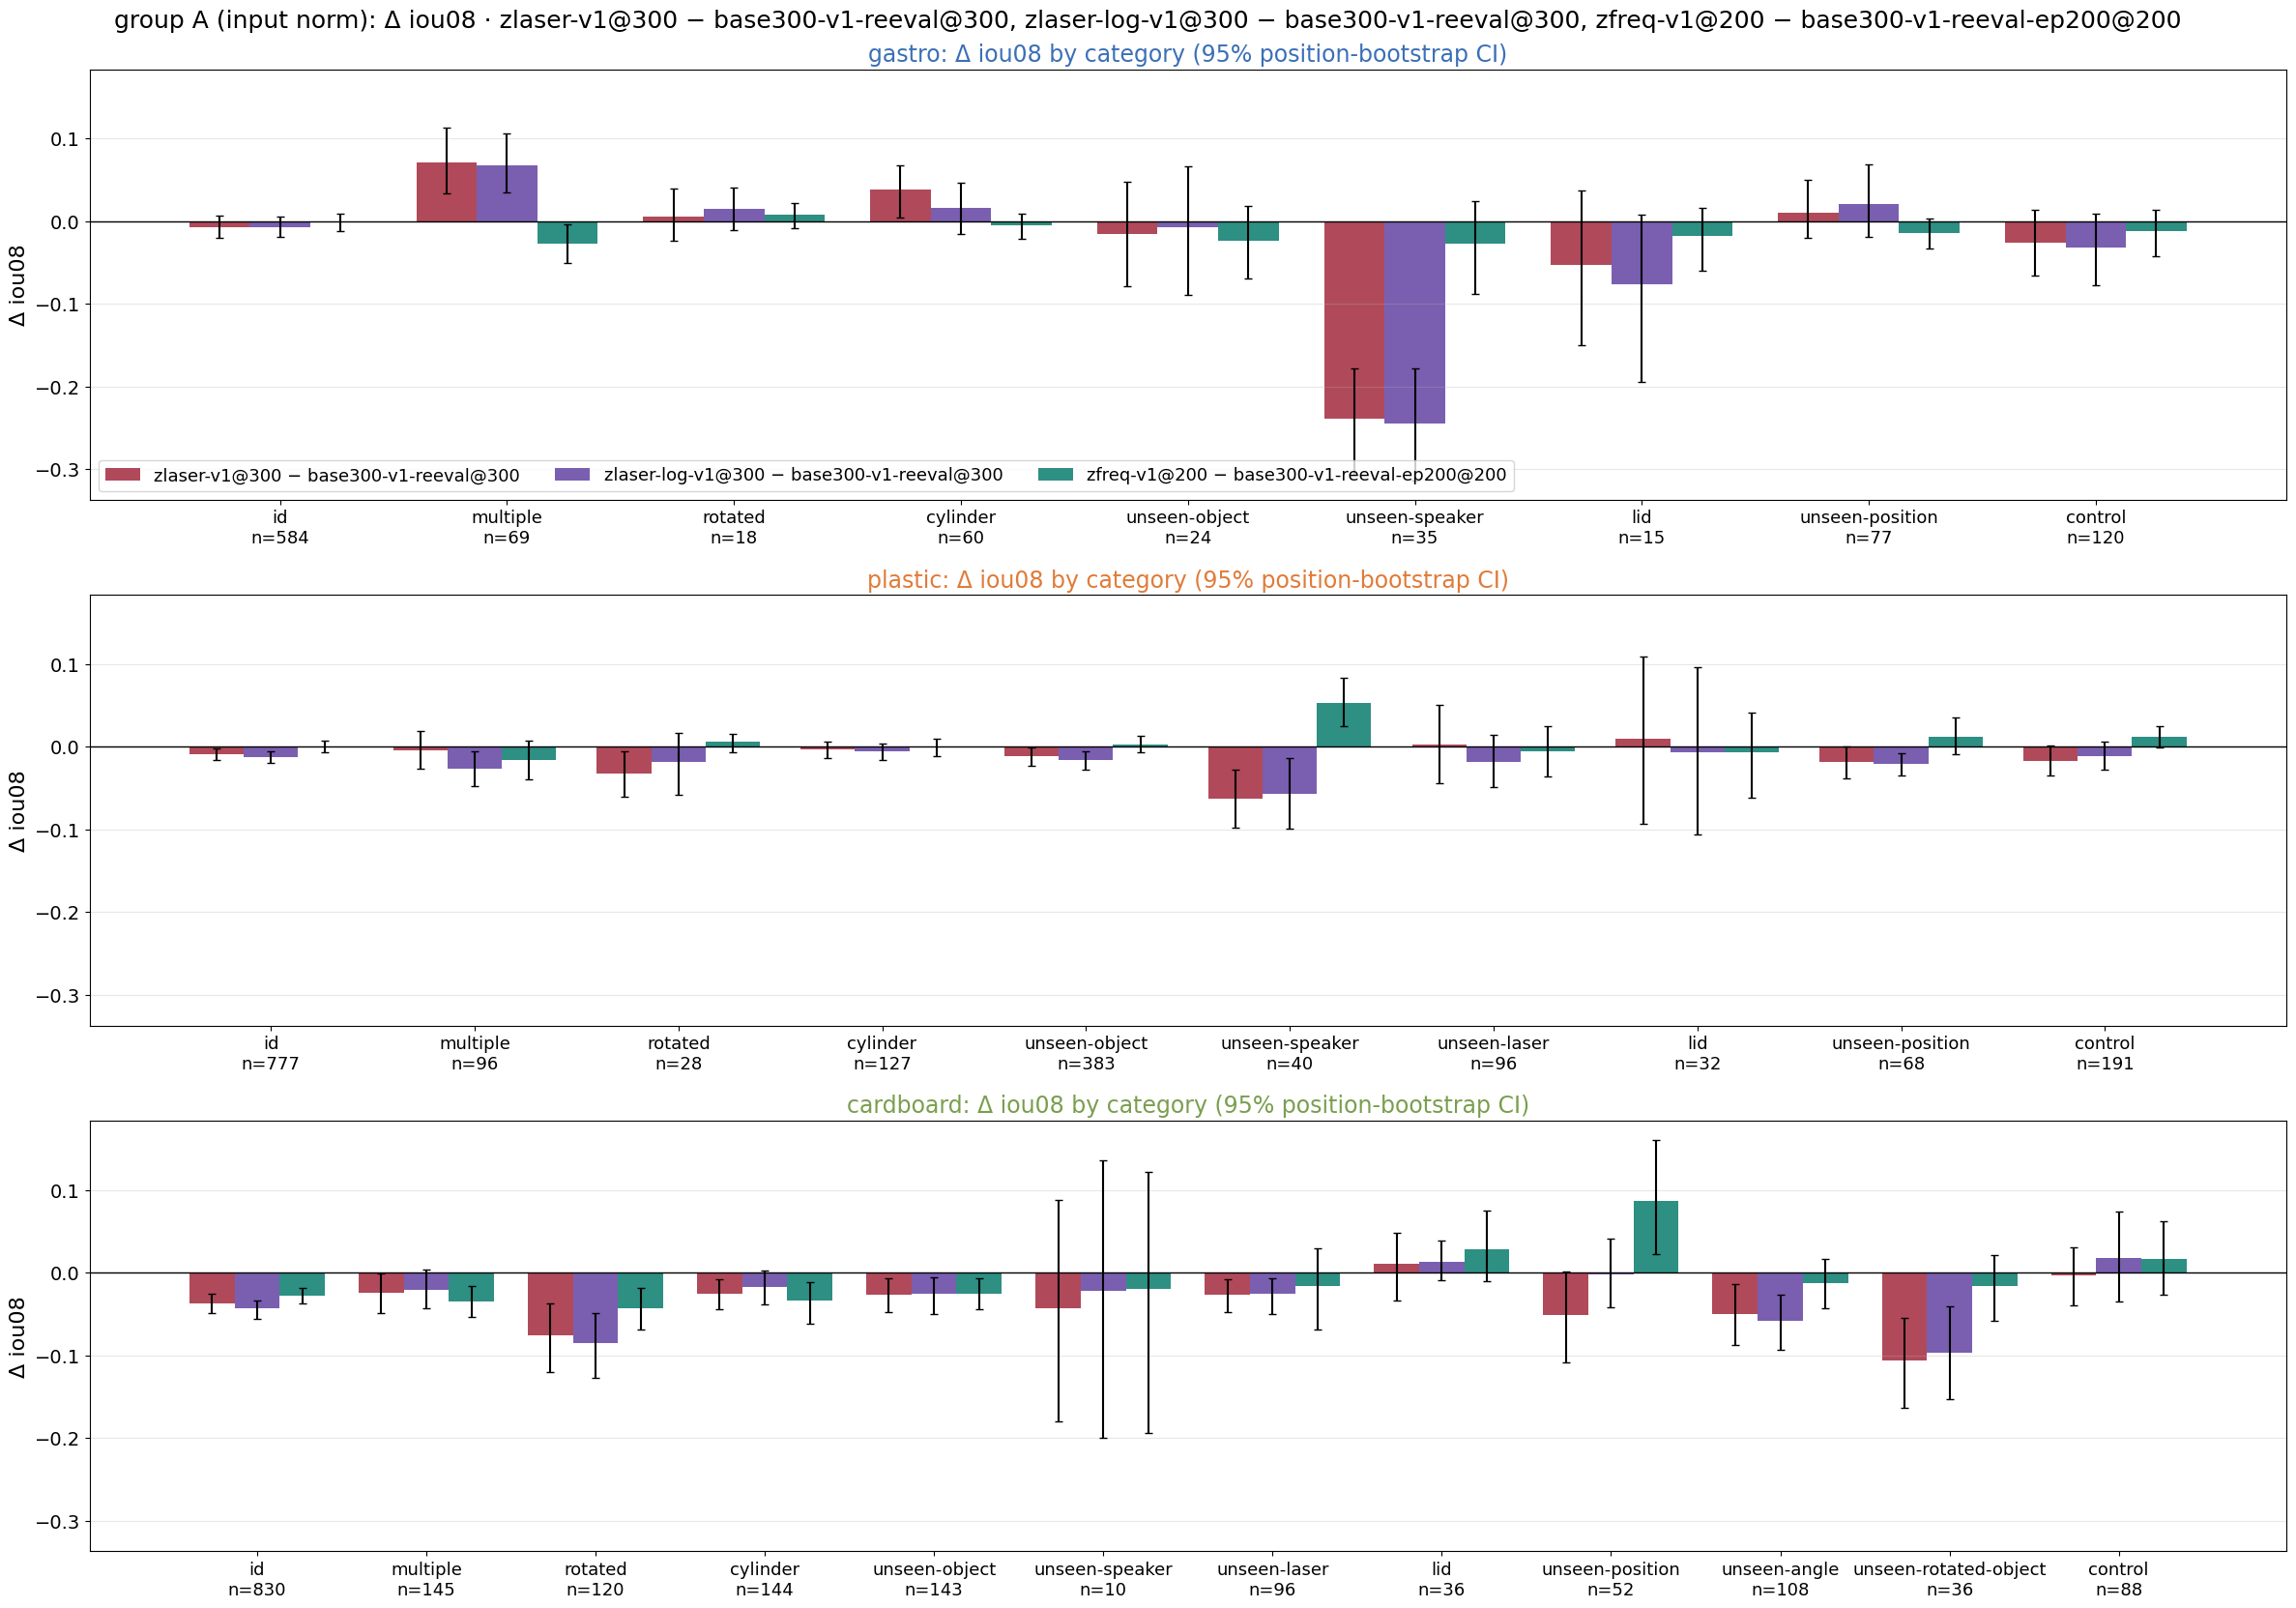

In [6]:
GA = GROUPS["A"]
print("A: paired Δ iou08 per slice (95% position-bootstrap CI; sig = CI excludes 0), Δ biou likewise")
display(delta_table(GA))
cat_plot(GA)

A: per split, robust wins (CI > 0) and the 6 worst splits; miss = fraction of samples with iou08 < .1


cat    n   base      d     lo     hi  miss_b  miss_r
run                                         kind       split                                                                                                         
zlaser-v1@300 vs base300-v1-reeval@300      robust win gastro/cube-vase                                     multiple   27  0.277  0.097  0.034  0.155   0.074   0.000
                                                       plastic/cube-shifted-lasers-3-backside           unseen-laser   32  0.057  0.085  0.007  0.184   0.812   0.562
                                                       gastro/cylinder-500g                                 cylinder   27  0.100  0.066  0.023  0.106   0.481   0.333
                                                       gastro/cube-without-lid                               control   15  0.464  0.058  0.015  0.088   0.000   0.000
                                                       gastro/two-cubes                                     multiple   42  0.260  0.054  0.005  0.107   0.238   0.071
                                                       gastro/cylinder-1000g                                cylinder   27  0.248  0.040  0.020  0.059   0.000   0.000
                                            worst      gastro/cube-unseen-speaker-unseen              unseen-speaker   35  0.334 -0.239 -0.307 -0.173   0.143   0.686
                                                       cardboard/cube-rotated                                rotated   20  0.486 -0.115 -0.380  0.042   0.050   0.100
                                                       cardboard/portable-charger-sideways     unseen-rotated-object   36  0.421 -0.106 -0.162 -0.052   0.028   0.167
                                                       gastro/cylinder-100g                                 cylinder    6  0.094 -0.094 -0.187  0.000   0.667   1.000
                                                       cardboard/cube                                             id  221  0.484 -0.089 -0.124 -0.056   0.100   0.213
                                                       cardboard/cylinder-1000g                             cylinder   28  0.245 -0.086 -0.136 -0.031   0.393   0.571
zlaser-log-v1@300 vs base300-v1-reeval@300  robust win gastro/cube-without-lid                               control   15  0.464  0.090  0.022  0.175   0.000   0.000
                                                       gastro/cube-vase                                     multiple   27  0.277  0.086  0.023  0.147   0.074   0.037
                                                       gastro/two-cubes                                     multiple   42  0.260  0.056  0.015  0.107   0.238   0.095
                                                       gastro/cylinder-1000g                                cylinder   27  0.248  0.036  0.017  0.055   0.000   0.000
                                            worst      gastro/cube-unseen-speaker-unseen              unseen-speaker   35  0.334 -0.245 -0.319 -0.173   0.143   0.657
                                                       cardboard/cube-rotated                                rotated   20  0.486 -0.132 -0.301 -0.024   0.050   0.200
                                                       cardboard/cube                                             id  221  0.484 -0.099 -0.129 -0.071   0.100   0.181
                                                       cardboard/portable-charger-sideways     unseen-rotated-object   36  0.421 -0.097 -0.154 -0.041   0.028   0.167
                                                       gastro/cylinder-100g                                 cylinder    6  0.094 -0.094 -0.187  0.000   0.667   1.000
                                                       cardboard/cylinder-1000g                             cylinder   28  0.245 -0.093 -0.141 -0.047   0.393   0.643
zfreq-v1@200 vs base300-v1-reeval-ep200@200 robust win cardboard/unseen-position                     unseen-position   52  0.497 

A: failure modes per slice (base300@300, base300@200, runs)


iou08   biou  area ratio (med)  under % (ar<.7)  over % (ar>1.5)  miss % (iou<.1)  multi: obj hit %  multi: obj ≥50% %  soft px %  extra px %
slice           run                                                                                                                                                                       
ID              base300-v1-reeval@300        0.680  0.551             1.093            4.278            2.719            2.119            79.032             50.000     25.634       3.215
                base300-v1-reeval-ep200@200  0.671  0.536             1.127            2.999            4.438            1.999            81.452             54.516     27.614       3.652
                zlaser-v1@300                0.663  0.533             1.073            6.717            1.479            3.279            76.935             50.645     23.071       2.960
                zlaser-log-v1@300            0.659  0.528             1.074            6.317            1.519            2.879            76.935             49.194     23.440       2.854
                zfreq-v1@200                 0.659  0.524             1.118            3.479            4.078            2.839            80.000             47.419     28.057       4.157
OOD             base300-v1-reeval@300        0.385  0.283             0.978           22.246           24.733           24.094               NaN                NaN     31.657      17.200
                base300-v1-reeval-ep200@200  0.387  0.283             1.027           19.403           27.434           23.241               NaN                NaN     34.451      18.183
                zlaser-v1@300                0.361  0.265             0.905           27.150           21.109           26.510               NaN                NaN     30.834      19.025
                zlaser-log-v1@300            0.357  0.263             0.882           30.277           19.616           27.647               NaN                NaN     31.257      18.974
                zfreq-v1@200                 0.377  0.276             1.014           18.834           26.510           24.591               NaN                NaN     36.795      22.474
cardboard ID    base300-v1-reeval@300        0.633  0.488             1.112            4.615            1.744            3.590            73.448             48.276     29.762       5.093
                base300-v1-reeval-ep200@200  0.621  0.469             1.144            3.385            3.897            3.282            75.862             50.345     31.630       5.925
                zlaser-v1@300                0.597  0.454             1.075           10.154            0.308            7.179            69.310             41.379     26.825       6.055
                zlaser-log-v1@300            0.593  0.448             1.081            8.410            0.308            6.051            71.034             41.724     27.164       5.727
                zfreq-v1@200                 0.592  0.439             1.158            3.590            4.000            5.333            75.172             42.069     32.991       7.488
cardboard OOD   base300-v1-reeval@300        0.314  0.233             0.917           35.519            8.561           39.526               NaN                NaN     42.265      25.932
                base300-v1-reeval-ep200@200  0.319  0.234             0.986           32.423           13.843           38.251               NaN                NaN     46.001      27.819
                zlaser-v1@300                0.279  0.210             0.750           46.630            2.732           42.259               NaN                NaN     40.503      27.488
                zlaser-log-v1@300            0.280  0.211             0.716           48.816            2.004           42.805               NaN                NaN     41.203      28.193
                zfreq-v1@200                 0.293  0.216             1.000           27.322           12.204         

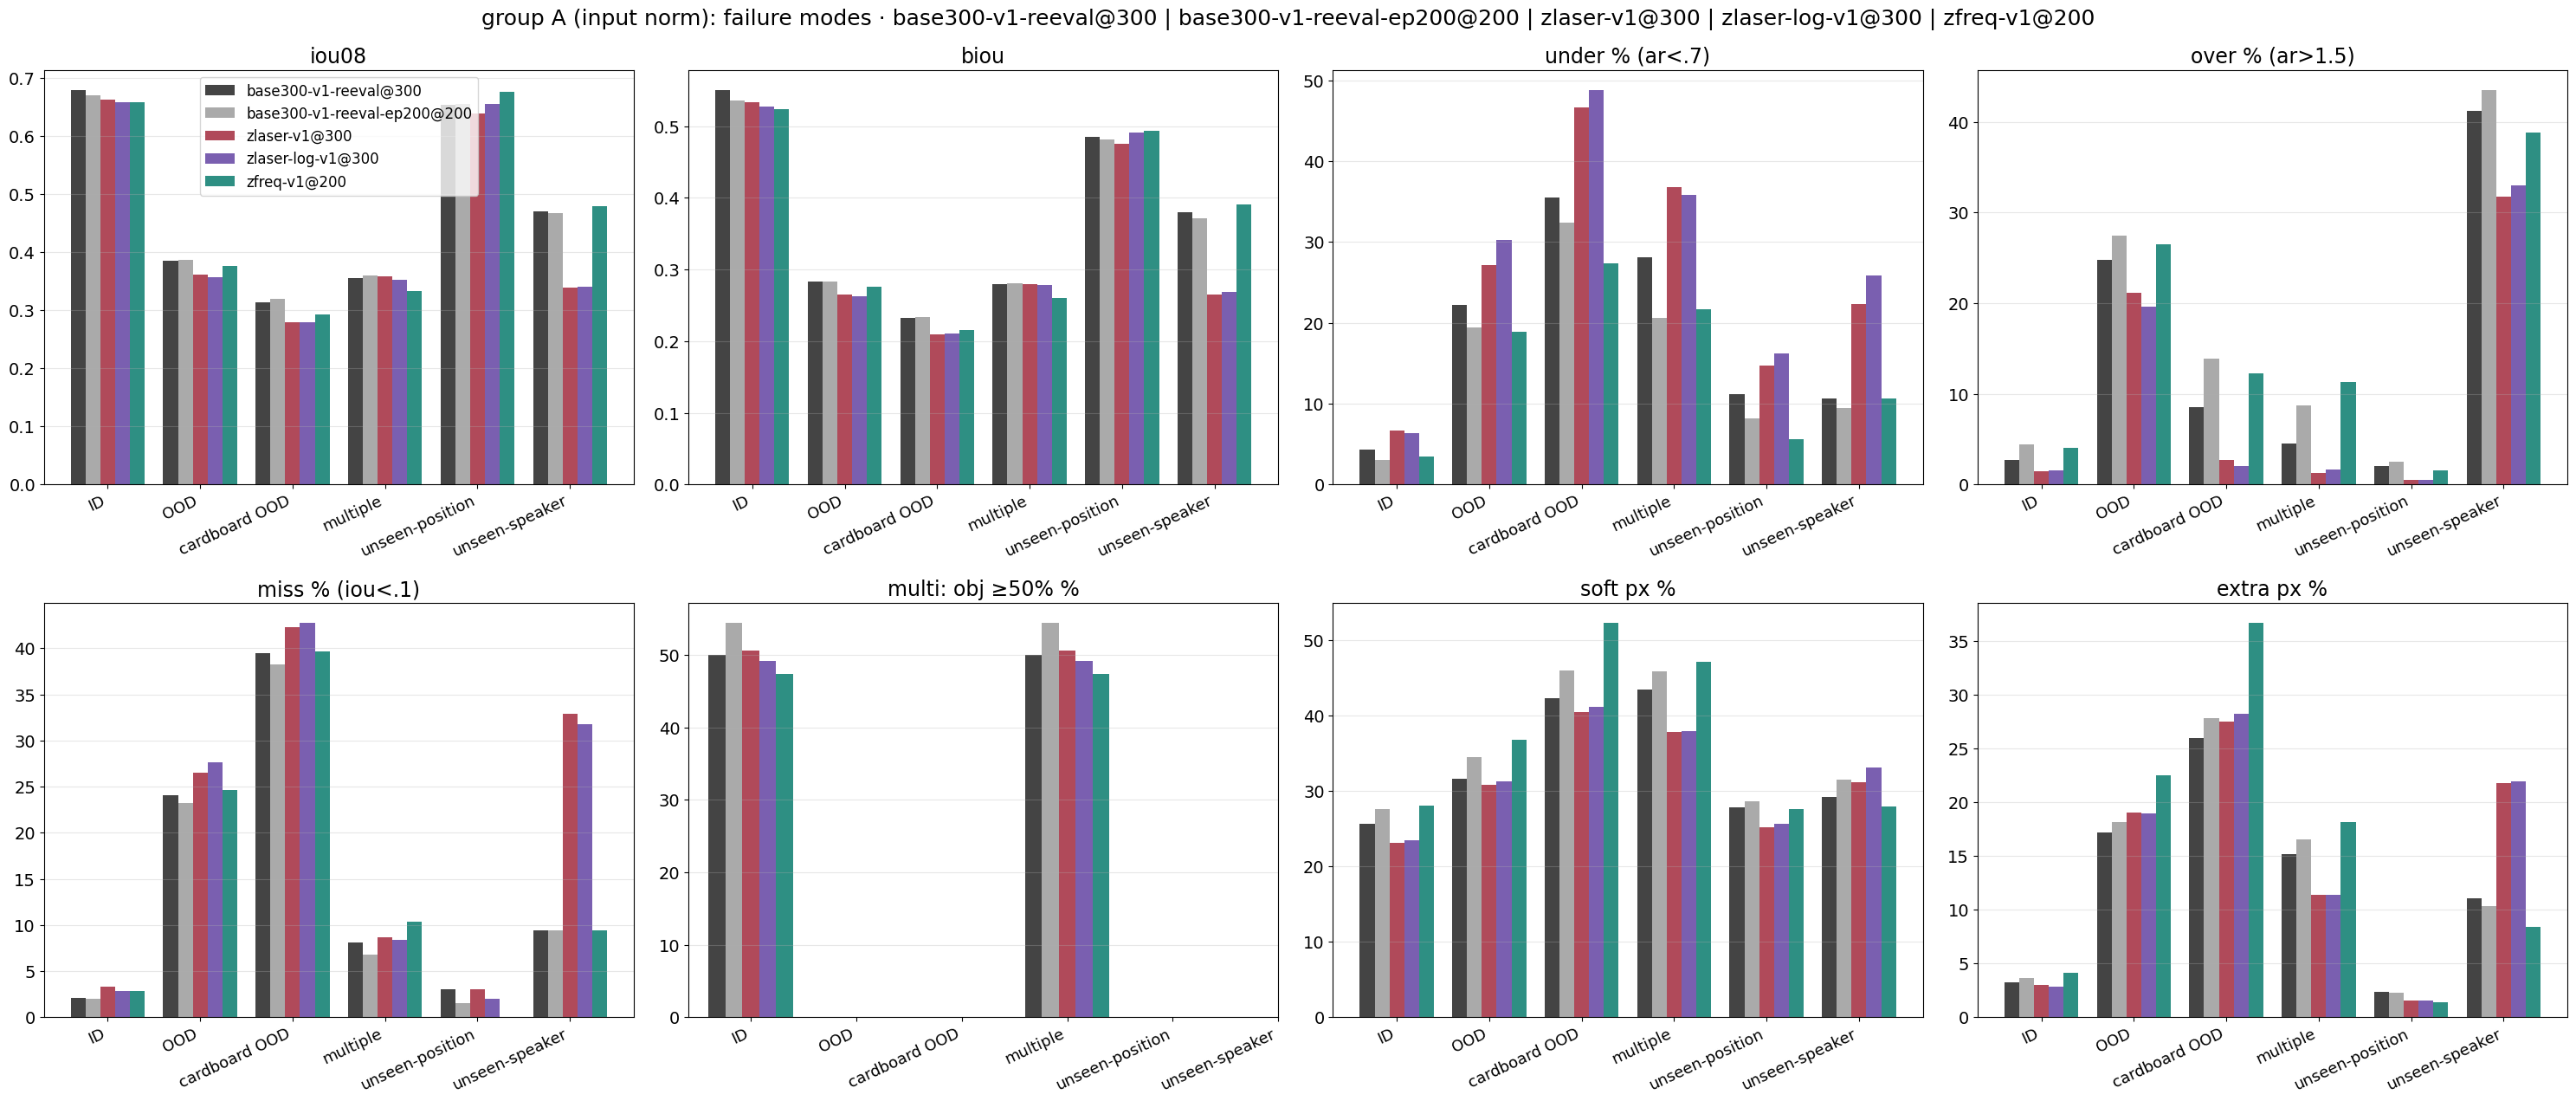

In [7]:
print("A: per split, robust wins (CI > 0) and the 6 worst splits; miss = fraction of samples with iou08 < .1")
display(split_table(GA))
print("A: failure modes per slice (base300@300, base300@200, runs)")
display(failure_table(GA, extra_base=BASE300_200))
failure_plot(GA, extra_base=BASE300_200)

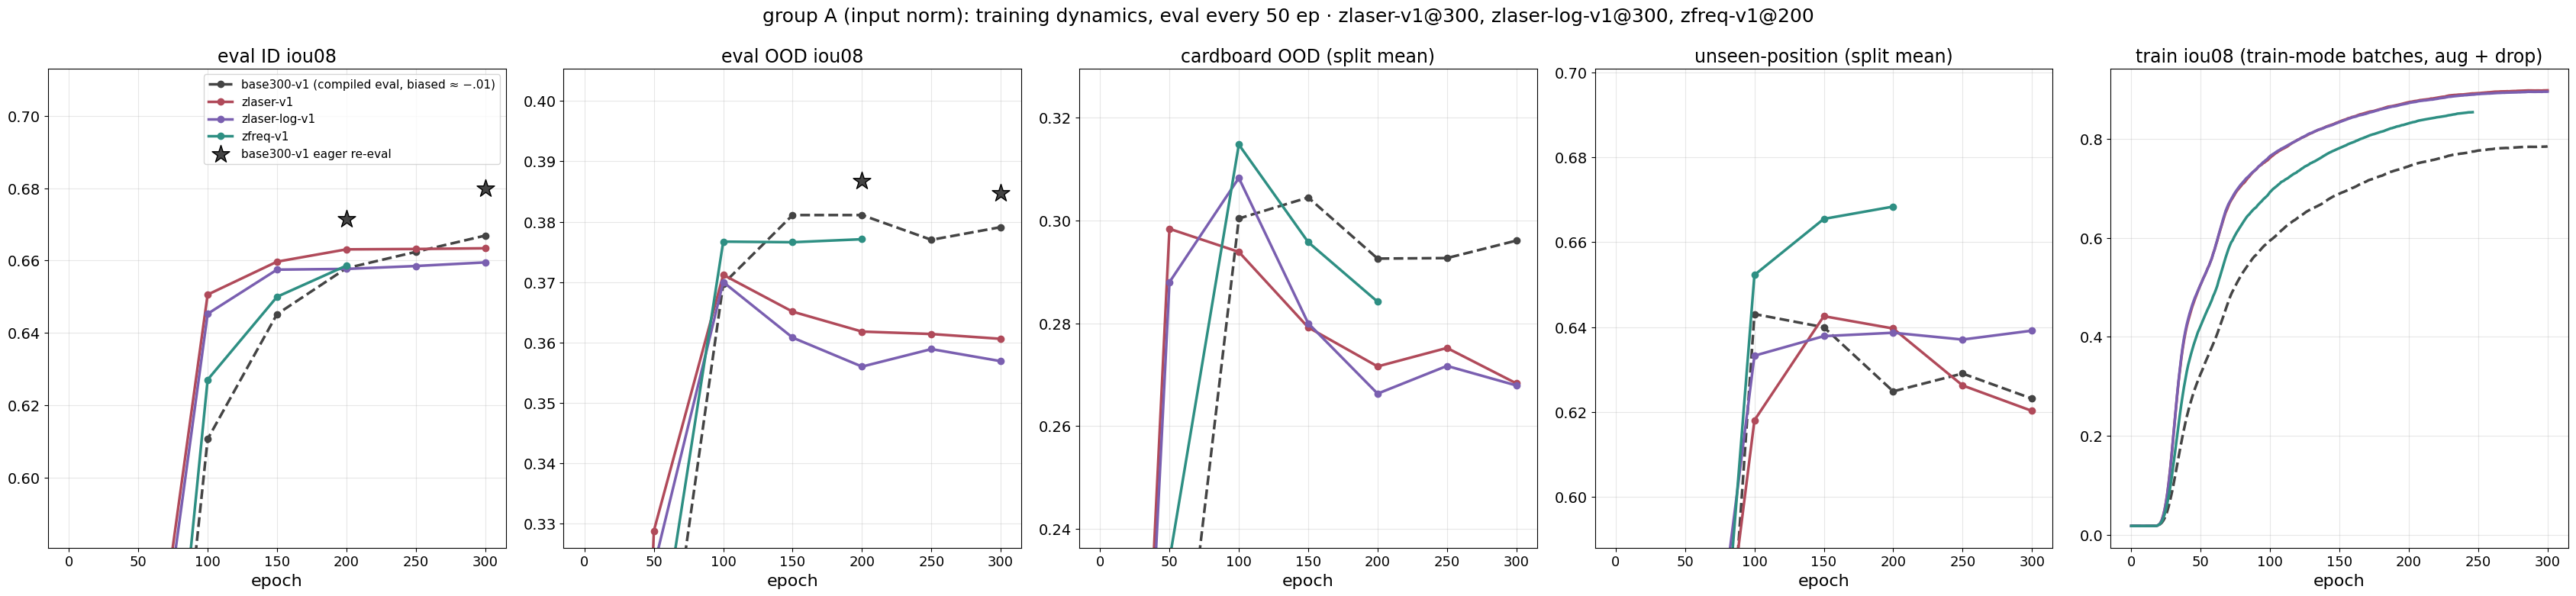

A: train-set fit (train-set eval saved post-fit, eval mode, eager) vs eval


,train-set iou08,train gastro,train plastic,train cardboard,eval ID,eval OOD,gap train − ID,note
run,,,,,,,,
base300-v1-reeval@300,0.854,0.883,0.897,0.809,0.680,0.385,0.174,NaN
zlaser-v1@300,0.898,0.907,0.917,0.880,0.663,0.361,0.235,NaN
zlaser-log-v1@300,0.895,0.902,0.912,0.879,0.659,0.357,0.236,NaN
zfreq-v1@200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no train-set eval saved (killed before the pos...


A: iou08 per slice over training (saved outputs, eager)


,ID,OOD,cardboard OOD,cardboard ID,gastro ID,plastic ID,multiple,unseen-position,unseen-speaker,unseen-object
run@ep,,,,,,,,,,
zlaser-v1@50,0.512,0.329,0.276,0.459,0.546,0.546,0.320,0.501,0.246,0.550
zlaser-v1@100,0.651,0.371,0.307,0.601,0.656,0.702,0.386,0.630,0.325,0.578
zlaser-v1@150,0.660,0.365,0.292,0.600,0.671,0.718,0.375,0.655,0.344,0.568
zlaser-v1@200,0.663,0.362,0.282,0.598,0.676,0.726,0.365,0.655,0.339,0.563
zlaser-v1@250,0.663,0.361,0.283,0.598,0.677,0.726,0.361,0.642,0.339,0.559
zlaser-v1@300,0.663,0.361,0.279,0.597,0.678,0.726,0.358,0.639,0.339,0.559
zlaser-log-v1@50,0.504,0.323,0.264,0.452,0.530,0.544,0.318,0.517,0.236,0.547
zlaser-log-v1@100,0.645,0.370,0.314,0.587,0.659,0.700,0.377,0.646,0.328,0.571
zlaser-log-v1@150,0.657,0.361,0.296,0.595,0.680,0.711,0.361,0.651,0.326,0.562


In [8]:
dyn_plot(GA, ["base300-v1"])
print("A: train-set fit (train-set eval saved post-fit, eval mode, eager) vs eval")
display(gap_table(GA))
# eager per-epoch slices from the saved outputs (every 50 ep): is there an early OOD peak?
rows = []
for r in ["zlaser-v1", "zlaser-log-v1", "zfreq-v1"]:
    for ep in [50, 100, 150, 200, 250, 300]:
        if not list((ROOT / f"runs/{r}/outputs_history/eval/gastro/cube").glob(f"ep{ep:04d}-*.pt")): continue
        S = EV.get((r, ep)); S = S if S is not None else per_sample(r, ep); EV[(r, ep)] = S
        rows.append({"run@ep": f"{r}@{ep}", **{k: S[m].iou.mean() for k, m in slices(S).items()}})
for b in [BASE300_200, BASE300]:
    rows.append({"run@ep": tag(b), **{k: EV[b][m].iou.mean() for k, m in slices(EV[b]).items()}})
print("A: iou08 per slice over training (saved outputs, eager)")
pd.DataFrame(rows).set_index("run@ep").round(3)

### A · mechanism checks on the inputs
These checks read about 1,600 spectra straight from the MDS cache and keep only small per-sample features in memory.
1. **What zlaser does to weak bins.** Under `sample` norm, a bin's spread across lasers keeps its natural size, so dead or low-SNR bins stay small. zlaser divides each bin by its across-laser std. That gives every bin unit spread, so it multiplies dead bins by up to ~30× (the gain range in decades is printed). The check measures what share of the input's across-laser variance comes from the weaker half of the bins: under sample norm vs exactly 50 % under zlaser.
2. **Unseen speaker.** zlaser's per-bin gain profile is speaker-specific. The check measures how far an unseen-speaker (speaker 4) sample's log-gain profile lies from the nearest train speaker's average profile, compared with how far a train sample lies from its own speaker's profile.
3. **What zfreq removes.** zfreq deletes each laser's overall level (the 100-value level map). A 5-fold ridge regression from the level map alone to the object CoM shows how much position information that map carries.

In [9]:
from dataset import load_splits, MDS
from streaming import StreamingDataset
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_predict
with contextlib.redirect_stdout(io.StringIO()): SAMPLES, IDXS = load_splits()
METAS = list(SAMPLES.values())
DS = StreamingDataset(local=str(MDS / "cache_tukey_64x64_19166c47fd09"), shuffle=False)
rng = np.random.default_rng(0)
tr = list(rng.choice([i for i in IDXS["train"] if METAS[i]["n_objects"] == 1], 1500, replace=False))
us = [i for b, s in [("gastro", "cube-unseen-speaker-unseen"), ("plastic", "cube-unseen-speaker-unseen"), ("cardboard", "vase-unseen-speaker-unseen")] for i in IDXS[f"eval/{b}/{s}"]]
F = []
for i in tr + us:
    row = DS[i]; x = row["X"].astype(np.float64); x = (x - x.mean()) / x.std()       # sample norm, (L,F,C)
    s = x.std(0)                                                                       # (F,C) across-laser spread = what zlaser divides by
    weak = s <= np.median(s)
    F.append(dict(i=i, box=METAS[i]["box"], spk=METAS[i]["speaker"], unseen=i in us, com=row["coms"][0],
                  weak_share=(s[weak] ** 2).sum() / (s ** 2).sum(), gain_decades=np.log10(np.percentile(s, 95) / np.percentile(s, 5)),
                  logg=np.log10(np.maximum(s, 1e-3 * np.median(s))), level=x.mean((1, 2))))
F = pd.DataFrame(F)
rows = []
for b, g in F.groupby("box"):
    t, u = g[~g.unseen], g[g.unseen]
    prof = {k: np.stack(t[t.spk == k].logg).mean(0) for k in sorted(t.spk.unique())}
    d = lambda a, p: np.sqrt(((a - p) ** 2).mean())
    lv, com = np.stack(t.level), np.stack(t.com)
    p = cross_val_predict(RidgeCV(alphas=np.logspace(-3, 3, 13)), lv, com, cv=5)
    r2 = 1 - ((p - com) ** 2).sum(0) / ((com - com.mean(0)) ** 2).sum(0)
    rows.append({"box": b, "n train / unseen-spk": f"{len(t)} / {len(u)}",
                 "1. weak-half share of across-laser variance, sample norm (zlaser = 50%)": 100 * t.weak_share.mean(),
                 "1. zlaser gain range p5→p95 (decades)": t.gain_decades.mean(),
                 "2. train → own speaker profile (RMS log10 gain)": np.mean([d(a, prof[k]) for a, k in zip(t.logg, t.spk)]),
                 "2. unseen speaker → nearest train speaker profile": np.mean([min(d(a, q) for q in prof.values()) for a in u.logg]),
                 "2. between train speaker profiles": np.mean([d(prof[a], prof[c]) for a in prof for c in prof if a < c]),
                 "3. ridge R² level map → CoM row": r2[0], "3. ridge R² level map → CoM col": r2[1]})
print("A mechanism checks (train samples with one object + every unseen-speaker eval sample), sample-normalized |X|")
pd.DataFrame(rows).set_index("box").T.round(3)

A mechanism checks (train samples with one object + every unseen-speaker eval sample), sample-normalized |X|


box,cardboard,gastronorm,green-plastic
n train / unseen-spk,699 / 10,317 / 35,484 / 40
"1. weak-half share of across-laser variance, sample norm (zlaser = 50%)",1.211001,0.764297,0.947497
1. zlaser gain range p5→p95 (decades),1.430893,1.548462,1.497272
2. train → own speaker profile (RMS log10 gain),0.068285,0.107021,0.092612
2. unseen speaker → nearest train speaker profile,0.140318,0.217576,0.165498
2. between train speaker profiles,0.190403,0.231173,0.199458
3. ridge R² level map → CoM row,0.085818,0.343745,0.4907
3. ridge R² level map → CoM col,0.442874,0.47914,0.546818


### A · findings
**zlaser-v1@300 / zlaser-log-v1@300** (ID −.017 / −.021, OOD −.024 / −.028; both outside the CI and above the noise scale)
- **Where it fails:**
  - **unseen speaker collapses**, −.13. On gastro the miss rate goes from 14 % to 69 %.
  - **cardboard** ID −.036 and OOD −.035, with rotated / unseen-rotated objects around −.1.
  - plastic is slightly worse.
  - Predictions **under-paint**: on cardboard OOD the under-predicted share (area ratio < .7) rises from 36 to 47 %, and the median area ratio drops from .92 to .75. Under-painting is the bad direction for this project.
  - biou falls by about as much as iou, so edges get no crisper.
- **Where it succeeds:** **gastro multi-object.** cube-vase +.097 and two-cubes +.054, both robust. In gastro ID, the share of objects ≥ 50 % covered rises from 29 to 49 %. gastro cylinders gain +.04–.07. Pooled `multiple` is flat because cardboard multiple goes down.
- **Dynamics: it overfits.**
  - It learns much faster and fits the train set better: train-set iou .898 vs .854, and the train − ID gap grows from .174 to .235.
  - OOD peaks at ep100 (.371) and then slides to .361. Cardboard OOD peaks at ep50–100 (~.31) and ends at .28.
  - Even the ep100 peak is below the eager baseline (OOD .385–.387), so early stopping would not rescue it.
- **Mechanism (measured):**
  - Under sample norm, the weaker half of the bins carries only **~1 %** of the across-laser variance. zlaser forces it to 50 %: noise bins are up-weighted 40–60×, with a per-bin gain spanning ~1.5 decades.
  - That gain is speaker-specific. An unseen speaker's gain profile is **2×** farther from the nearest train speaker than a train sample is from its own speaker. So the model sees a reweighting it has never seen, and the unseen-speaker split breaks.
  - log-mag on top changes nothing.

**zfreq-v1@200 vs base300@200** (ID −.013, OOD −.010)
- The "flat OOD" is not a win. base300@200 is also flat at .387 and is higher.
- **Where it succeeds:**
  - **unseen-position +.022**: cardboard +.087, with misses going from 6 % to 0 %.
  - plastic unseen-speaker +.053 and plastic portable-charger +.049.
  - It is the model *least* pulled toward a seen vase position (B check 1: 9.2 px from the vase prior vs 8.4 for base@200).
- **Where it fails:**
  - multiple −.028;
  - cardboard ID −.029 and OOD −.026;
  - cardboard vase-laser-shifted-2 −.11.
  - It over-paints mushier masks on cardboard OOD: soft px 52 vs 46 %, extra px 37 vs 28 %.
- **Dynamics:** still rising at ep200 (ID +.009 over ep150→200). The baseline also gained +.009 over ep200→300, so a full run would probably still trail on ID.
- **Mechanism:** the per-laser level map it deletes carries position. A ridge regression from it alone reaches R² .09–.49 (row) and .44–.55 (col). Losing that cue costs where objects are dense (cardboard, multiple), while helping interpolation into the held-out vase region.

## B · Readouts (vs drop30-v1-reeval@300)
**Confound.** The three readout runs differ from drop30-v1 in more than the readout:

| | drop30-v1 (baseline) | pool / cls | query |
|---|---|---|---|
| readout | per | pool / cls | query (16 queries, 1 layer) |
| abspos | 0 | **1** | **1** |
| d / heads | 256 / 8 | **400 / 10** | **336 / 7** |
| microbatch | 128 | **64** | **64** |

All runs share drop .3 / .3, lr 1e-4, batch 1024, 300 ep. Microbatch is gradient accumulation within the 1024 batch. It only matters through the decoder's BatchNorm batch statistics (64 vs 128), which is minor. abspos and the width do change the model. So group B compares a *bundle*: {readout, abspos, a wider model} vs per / no abspos / d256. Nothing here can attribute the drop to the readout alone, although the −.14 to −.17 ID drop is far outside any noise.

B: paired Δ iou08 per slice (95% position-bootstrap CI)


n   base  run_iou  d_iou     lo     hi sig  d_biou biou_sig
run                   vs                   slice                                                                          
pool-abspos-m-v1@300  drop30-v1-reeval@300 ID               2501  0.671    0.511 -0.160 -0.172 -0.149   -  -0.165        -
                                           OOD              1407  0.385    0.315 -0.071 -0.087 -0.055   -  -0.052        -
                                           cardboard OOD     549  0.317    0.167 -0.149 -0.183 -0.117   -  -0.112        -
                                           cardboard ID      975  0.622    0.378 -0.244 -0.262 -0.226   -  -0.233        -
                                           gastro ID         653  0.671    0.530 -0.141 -0.162 -0.120   -  -0.152        -
                                           plastic ID        873  0.727    0.646 -0.081 -0.093 -0.070   -  -0.099        -
                                           multiple          310  0.349    0.170 -0.178 -0.205 -0.151   -  -0.140        -
                                           unseen-position   197  0.654    0.433 -0.221 -0.281 -0.165   -  -0.170        -
                                           unseen-speaker     85  0.465    0.424 -0.040 -0.087  0.004      -0.013         
                                           unseen-object     550  0.579    0.506 -0.073 -0.101 -0.047   -  -0.060        -
cls-abspos-m-v1@300   drop30-v1-reeval@300 ID               2501  0.671    0.529 -0.143 -0.154 -0.132   -  -0.143        -
                                           OOD              1407  0.385    0.315 -0.071 -0.087 -0.055   -  -0.053        -
                                           cardboard OOD     549  0.317    0.171 -0.146 -0.178 -0.114   -  -0.108        -
                                           cardboard ID      975  0.622    0.388 -0.234 -0.252 -0.216   -  -0.222        -
                                           gastro ID         653  0.671    0.564 -0.107 -0.126 -0.089   -  -0.112        -
                                           plastic ID        873  0.727    0.660 -0.067 -0.080 -0.056   -  -0.080        -
                                           multiple          310  0.349    0.186 -0.163 -0.188 -0.136   -  -0.125        -
                                           unseen-position   197  0.654    0.426 -0.228 -0.282 -0.176   -  -0.180        -
                                           unseen-speaker     85  0.465    0.437 -0.028 -0.070  0.011      -0.004         
                                           unseen-object     550  0.579    0.506 -0.073 -0.101 -0.046   -  -0.062        -
query-abspos-m-v1@300 drop30-v1-reeval@300 ID               2501  0.671    0.499 -0.172 -0.184 -0.161   -  -0.172        -
                                           OOD              1407  0.385    0.310 -0.076 -0.092 -0.060   -  -0.055        -
                                           cardboard OOD     549  0.317    0.164 -0.153 -0.189 -0.120   -  -0.115        -
                                           cardboard ID      975  0.622    0.358 -0.264 -0.282 -0.245   -  -0.247        -
                                           gastro ID         653  0.671    0.541 -0.130 -0.151 -0.111   -  -0.138        -
                                           plastic ID        873  0.727    0.627 -0.100 -0.115 -0.086   -  -0.114        -
                                           multiple          310  0.349    0.163 -0.186 -0.213 -0.157   -  -0.143        -
                                           unseen-position   197  0.654    0.446 -0.208 -0.265 -0.155   -  -0.158        -
                                           unseen-speaker     85  0.465    0.437 -0.027 -0.066  0.010      -0.007         
                                           unseen-object     550  0.579    0.497 -0.082 -0.113 -0.054   -  -0.067        -

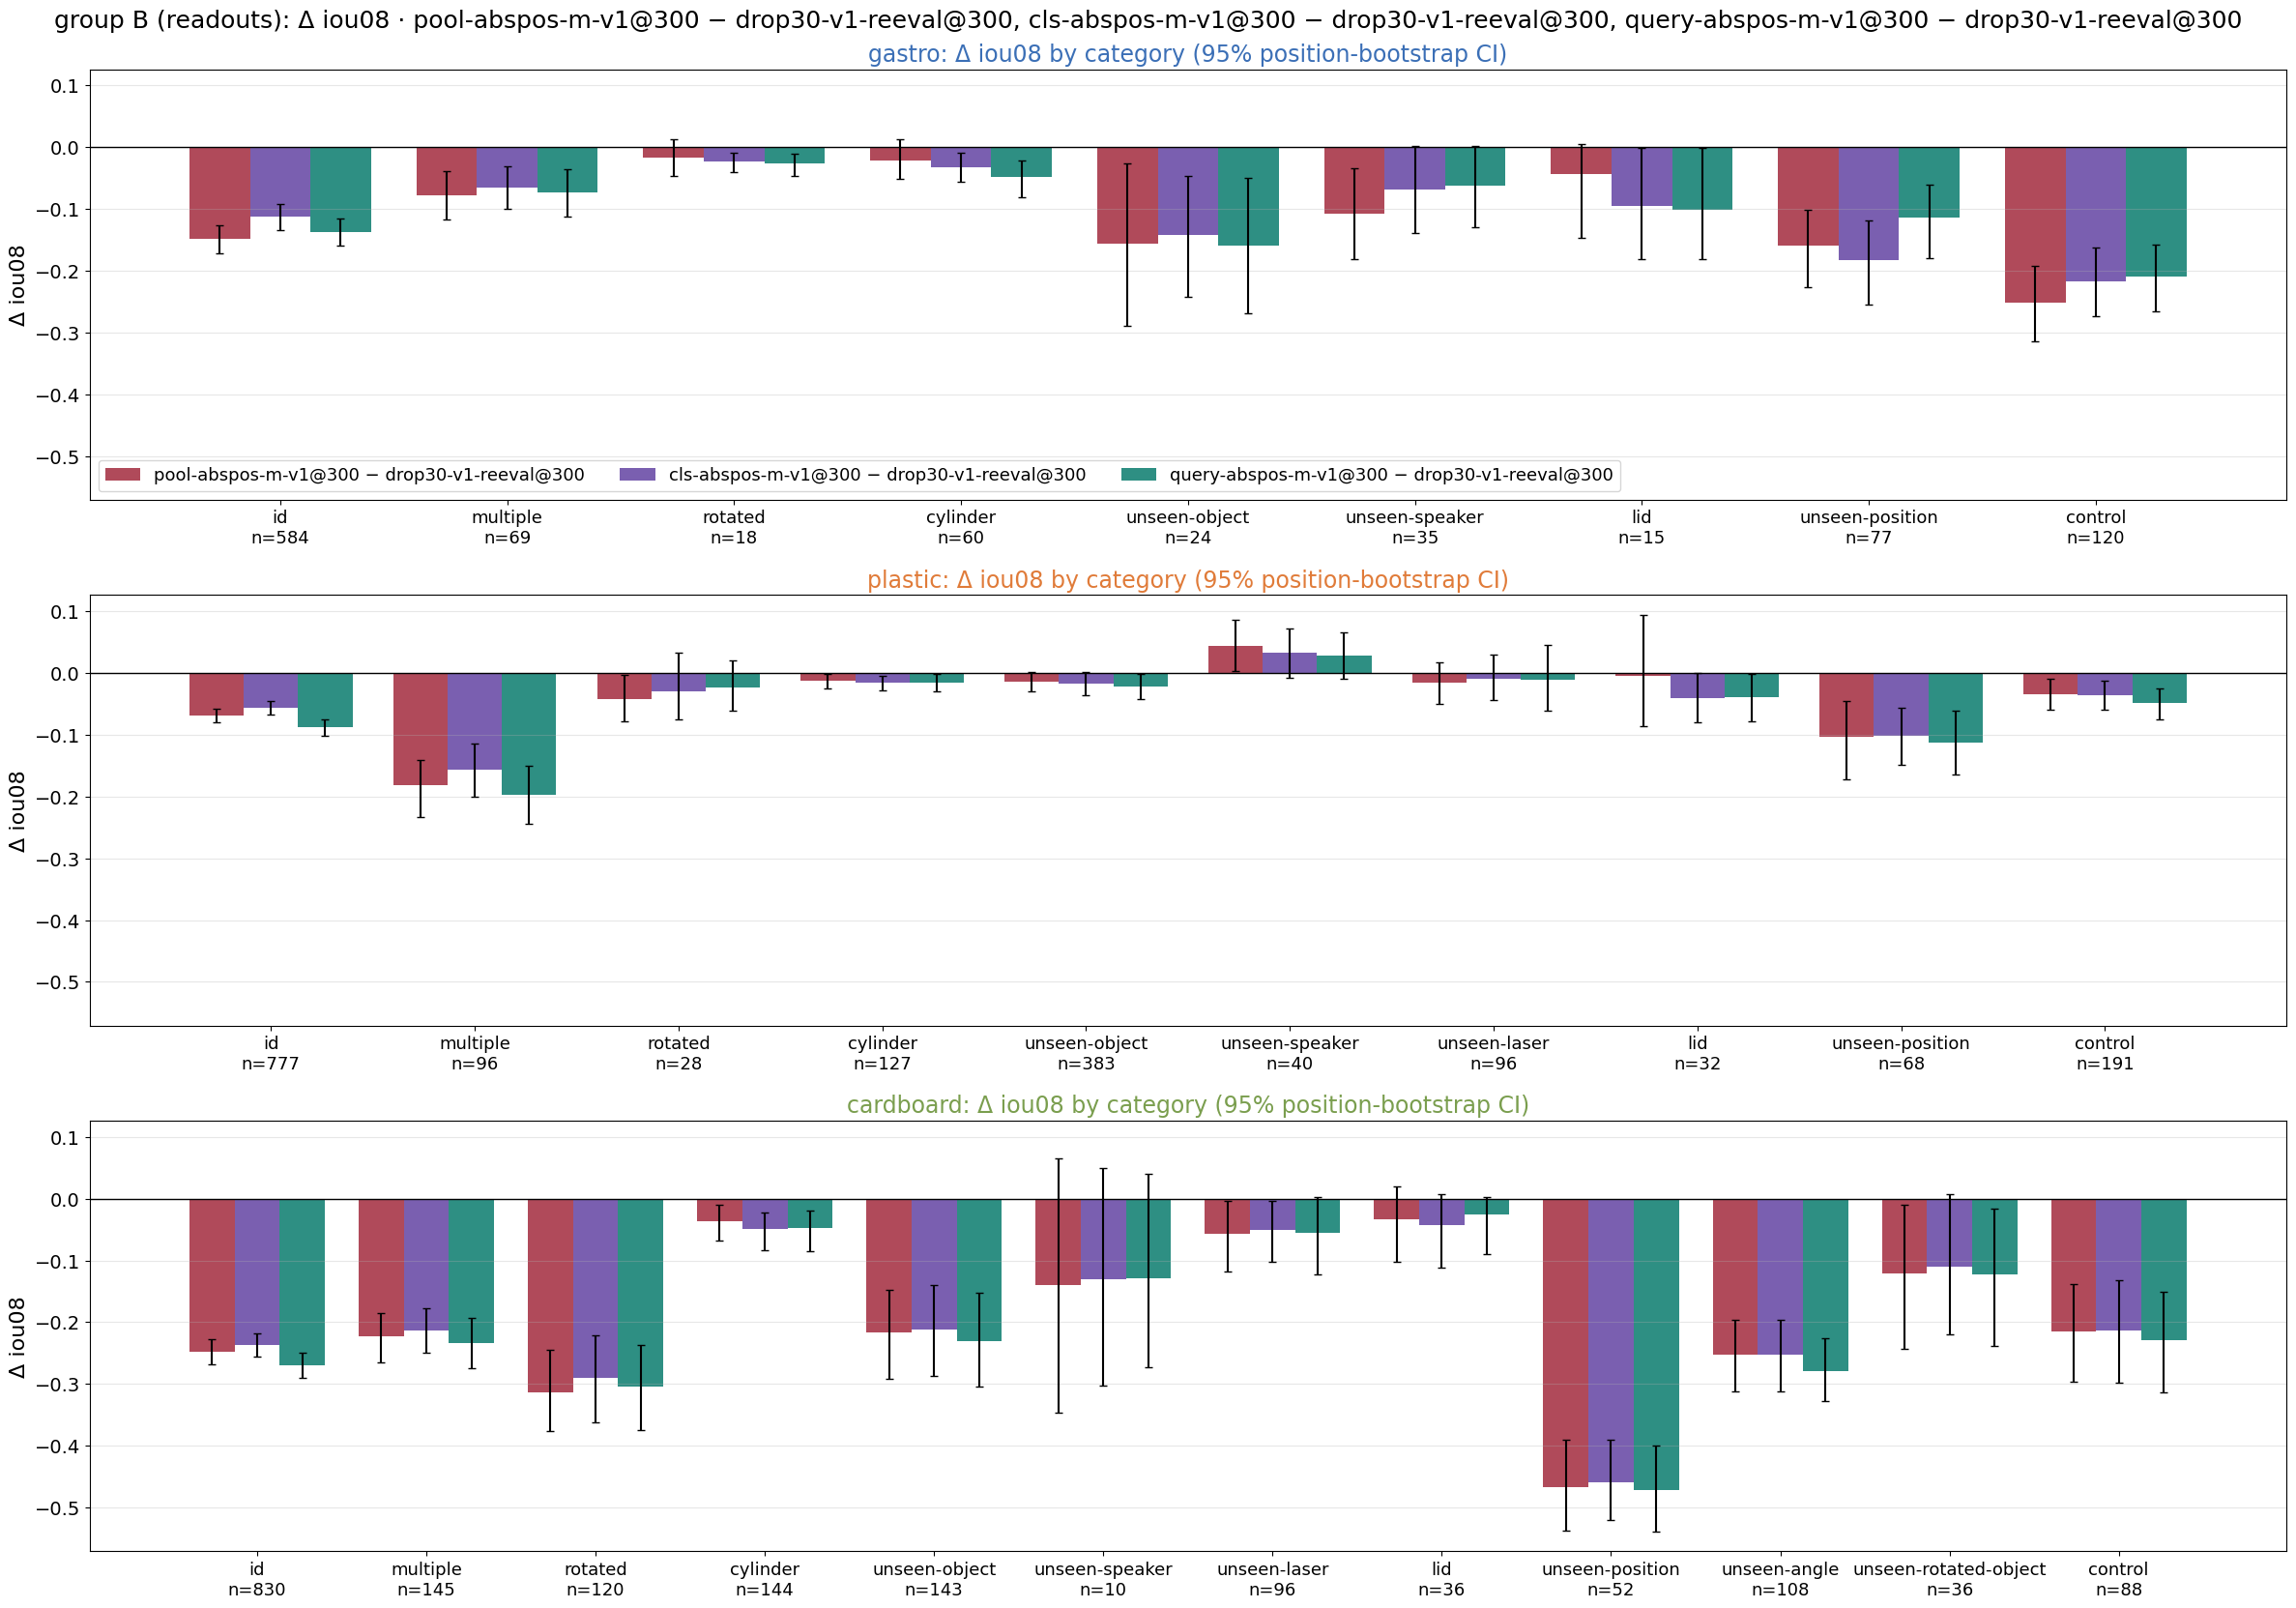

B: per split, robust wins and the 6 worst splits


cat    n   base      d     lo     hi  miss_b  miss_r
run                                           kind       split                                                                                                
pool-abspos-m-v1@300 vs drop30-v1-reeval@300  robust win plastic/portable-charger               unseen-object   40  0.307  0.057  0.011  0.113   0.100   0.075
                                                         plastic/cube-unseen-speaker-unseen    unseen-speaker   40  0.616  0.043  0.001  0.086   0.000   0.000
                                                         cardboard/vase-laser-shifted-3          unseen-laser   36  0.006  0.035  0.001  0.081   0.972   0.889
                                              worst      cardboard/unseen-position            unseen-position   52  0.514 -0.466 -0.533 -0.391   0.038   0.865
                                                         cardboard/cube-rotated                       rotated   20  0.520 -0.407 -0.558 -0.219   0.000   0.600
                                                         cardboard/cube                                    id  221  0.465 -0.296 -0.339 -0.252   0.100   0.520
                                                         cardboard/soap-dispenser-rotated             rotated  100  0.559 -0.294 -0.373 -0.219   0.000   0.380
                                                         gastro/cube-unseen-speaker-baseline          control  105  0.555 -0.281 -0.347 -0.217   0.029   0.229
                                                         cardboard/coffee-pot                   unseen-object   36  0.629 -0.273 -0.443 -0.111   0.000   0.278
cls-abspos-m-v1@300 vs drop30-v1-reeval@300   robust win plastic/portable-charger               unseen-object   40  0.307  0.066  0.008  0.130   0.100   0.025
                                              worst      cardboard/unseen-position            unseen-position   52  0.514 -0.458 -0.521 -0.389   0.038   0.808
                                                         cardboard/cube-rotated                       rotated   20  0.520 -0.398 -0.519 -0.241   0.000   0.550
                                                         cardboard/coffee-pot                   unseen-object   36  0.629 -0.287 -0.446 -0.131   0.000   0.333
                                                         cardboard/cube                                    id  221  0.465 -0.287 -0.329 -0.247   0.100   0.529
                                                         cardboard/soap-dispenser-rotated             rotated  100  0.559 -0.269 -0.347 -0.192   0.000   0.330
                                                         cardboard/soap-dispenser                          id  215  0.669 -0.259 -0.297 -0.222   0.000   0.107
query-abspos-m-v1@300 vs drop30-v1-reeval@300 robust win cardboard/vase-laser-shifted-3          unseen-laser   36  0.006  0.054  0.004  0.125   0.972   0.861
                                              worst      cardboard/unseen-position            unseen-position   52  0.514 -0.472 -0.542 -0.398   0.038   0.885
                                                         cardboard/cube-rotated                       rotated   20  0.520 -0.426 -0.557 -0.267   0.000   0.550
                                                         cardboard/cube                                    id  221  0.465 -0.308 -0.351 -0.266   0.100   0.593
                                                         cardboard/soap-dispenser                          id  215  0.669 -0.296 -0.343 -0.251   0.000   0.144
                                                         cardboard/biscoff                      unseen-object   36  0.518 -0.290 -0.442 -0.126   0.000   0.444
                                                         cardboard/soap-dispenser-rotated             rotated  100  0.559 -0.279 -0.359 -0.205   0.000   0.380

B: failure modes per slice


iou08   biou  area ratio (med)  under % (ar<.7)  over % (ar>1.5)  miss % (iou<.1)  multi: obj hit %  multi: obj ≥50% %  soft px %  extra px %
slice           run                                                                                                                                                                 
ID              drop30-v1-reeval@300   0.671  0.539             1.111            3.279            3.479            2.239            80.000             48.065     28.722       3.487
                pool-abspos-m-v1@300   0.511  0.374             1.127            8.836           11.875           12.795            56.774             22.581     38.948      14.237
                cls-abspos-m-v1@300    0.529  0.395             1.100            8.397            8.557           11.835            57.742             23.871     35.514      12.420
                query-abspos-m-v1@300  0.499  0.367             1.103           10.236            9.596           13.754            52.742             21.613     36.252      14.440
OOD             drop30-v1-reeval@300   0.385  0.283             1.011           20.611           27.150           23.667               NaN                NaN     34.868      18.319
                pool-abspos-m-v1@300   0.315  0.231             1.025           20.753           28.429           35.110               NaN                NaN     42.640      31.852
                cls-abspos-m-v1@300    0.315  0.229             0.955           24.876           25.657           34.968               NaN                NaN     40.392      30.802
                query-abspos-m-v1@300  0.310  0.228             0.962           25.373           26.155           36.318               NaN                NaN     40.287      31.974
cardboard ID    drop30-v1-reeval@300   0.622  0.472             1.124            4.000            3.385            3.385            76.207             46.552     33.764       5.656
                pool-abspos-m-v1@300   0.378  0.239             1.198            9.641           20.000           23.077            43.793             15.172     53.708      27.187
                cls-abspos-m-v1@300    0.388  0.251             1.141            9.846           12.205           22.667            43.793             14.483     48.403      24.317
                query-abspos-m-v1@300  0.358  0.226             1.161           11.590           13.744           25.846            41.724             15.172     50.058      28.302
cardboard OOD   drop30-v1-reeval@300   0.317  0.234             0.978           33.515           12.933           38.616               NaN                NaN     46.499      27.295
                pool-abspos-m-v1@300   0.167  0.121             0.989           31.694           22.951           62.295               NaN                NaN     62.193      55.295
                cls-abspos-m-v1@300    0.171  0.125             0.875           38.980           16.576           61.202               NaN                NaN     57.946      52.669
                query-abspos-m-v1@300  0.164  0.118             0.875           37.341           17.851           62.842               NaN                NaN     61.067      56.055
gastro ID       drop30-v1-reeval@300   0.671  0.563             1.108            3.522            2.757            3.369            73.188             29.710     29.049       3.767
                pool-abspos-m-v1@300   0.530  0.411             1.071           10.720            6.432           11.485            55.072             23.188     33.122      10.237
                cls-abspos-m-v1@300    0.564  0.451             1.068            8.116            4.441            9.342            57.971             23.913     30.970       7.956
                query-abspos-m-v1@300  0.541  0.425             1.074           10.720            5.360           10.107            57.971             23.913     30.930       8.328
multiple        drop30-v1-reeval@300   0.349  0.274      

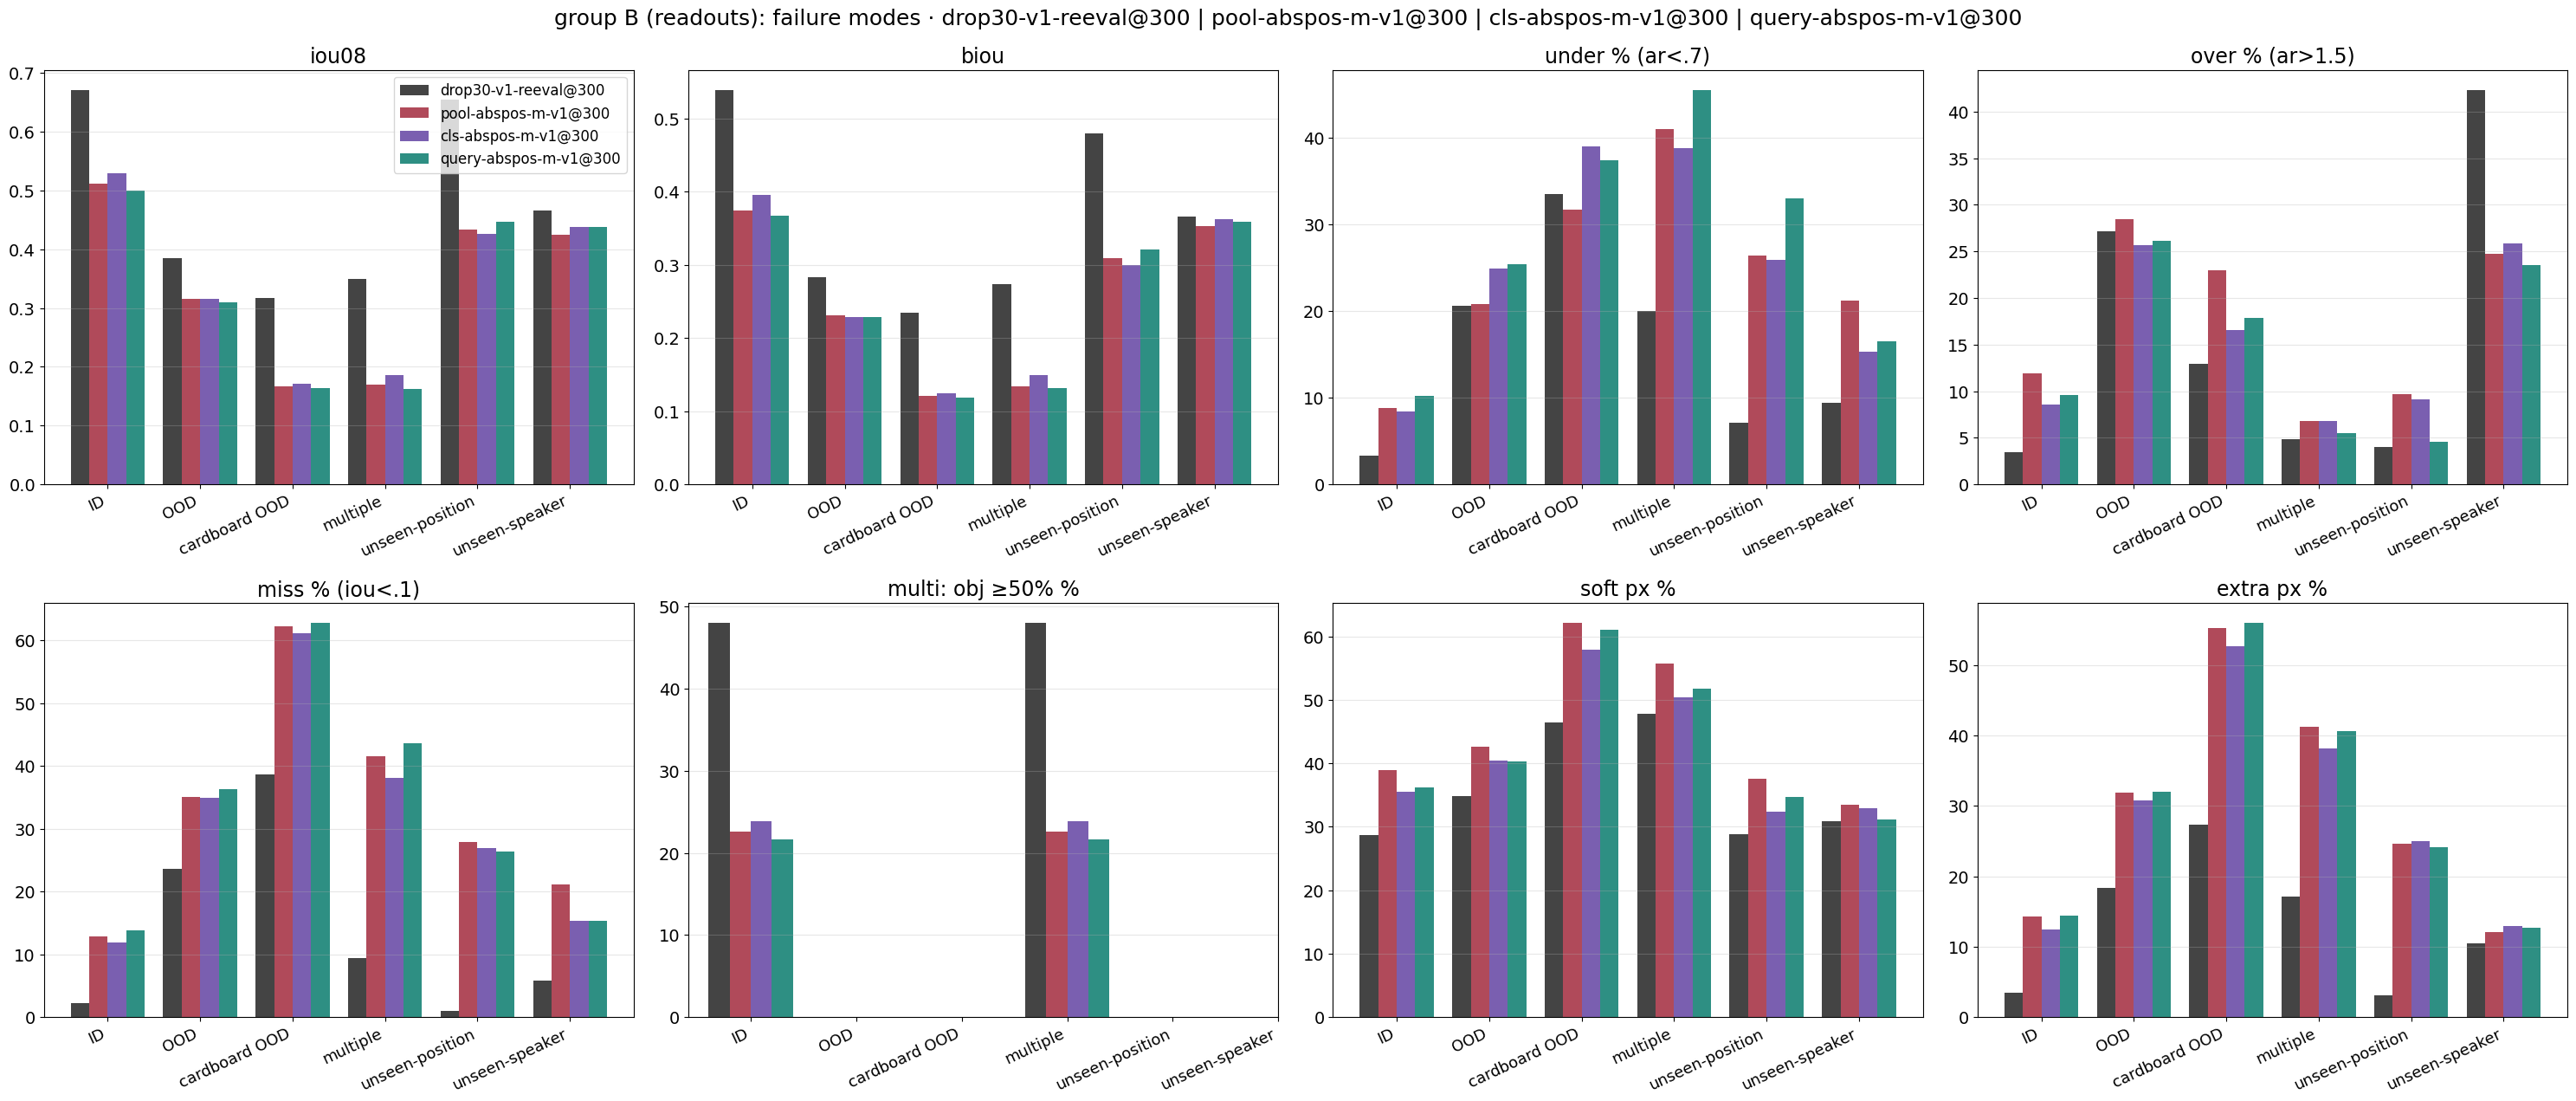

In [10]:
GB = GROUPS["B"]
print("B: paired Δ iou08 per slice (95% position-bootstrap CI)")
display(delta_table(GB))
cat_plot(GB)
print("B: per split, robust wins and the 6 worst splits")
display(split_table(GB))
print("B: failure modes per slice")
display(failure_table(GB))
failure_plot(GB)

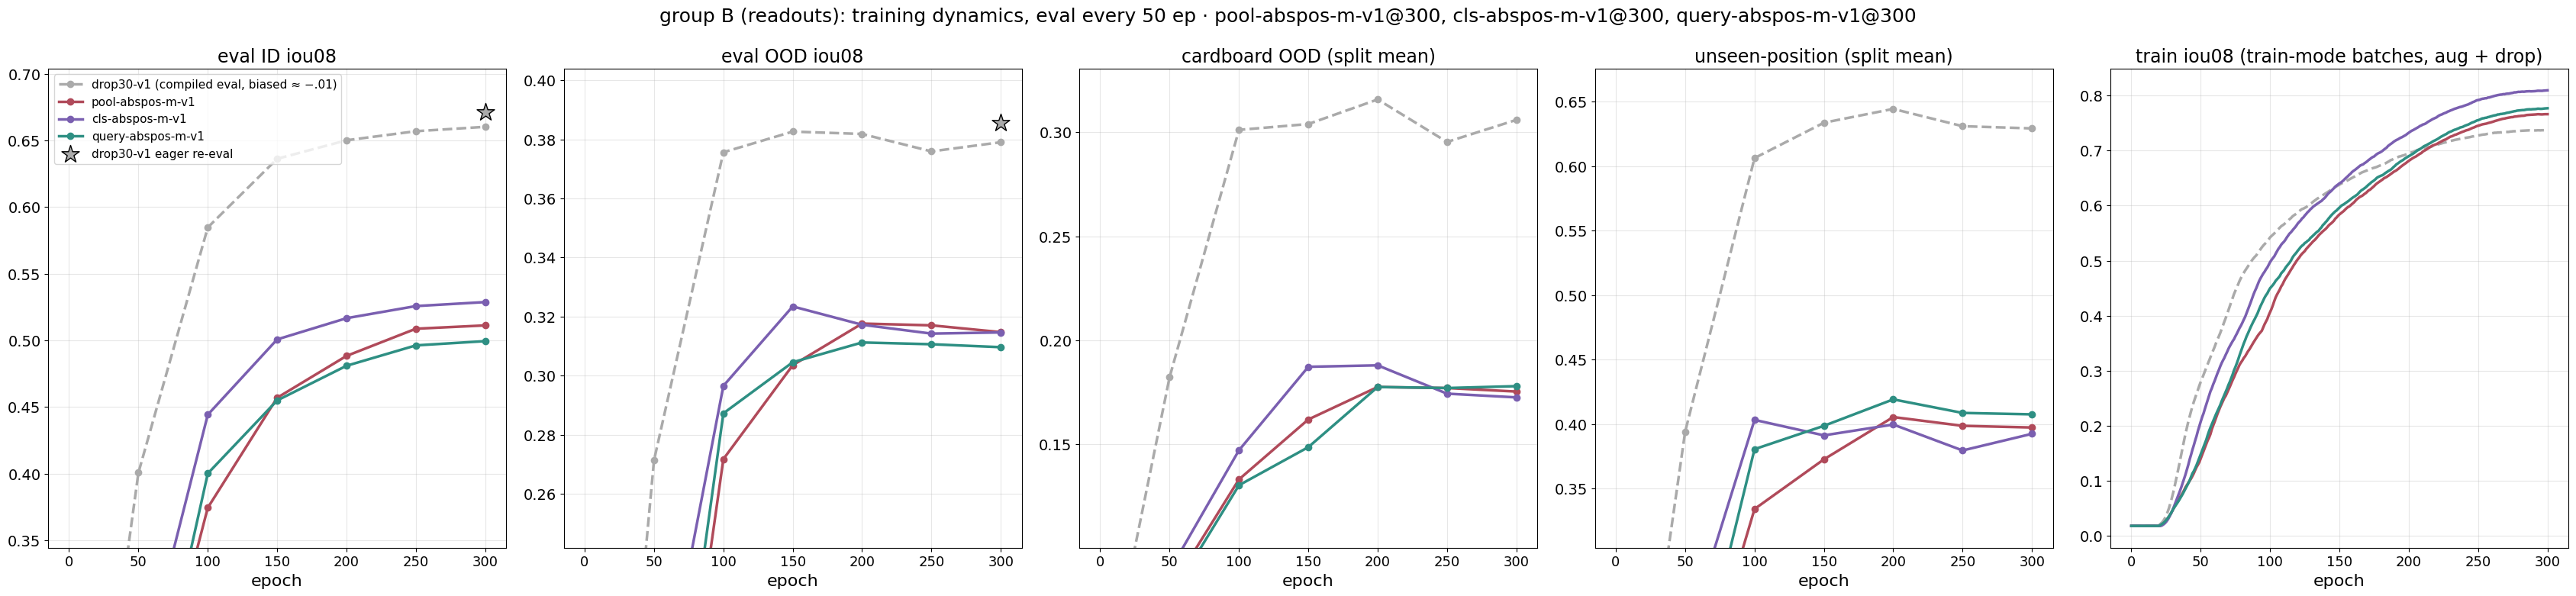

B: train-set fit vs eval


,train-set iou08,train gastro,train plastic,train cardboard,eval ID,eval OOD,gap train − ID
run,,,,,,,
drop30-v1-reeval@300,0.824,0.856,0.880,0.769,0.671,0.385,0.153
pool-abspos-m-v1@300,0.767,0.844,0.861,0.661,0.511,0.315,0.256
cls-abspos-m-v1@300,0.809,0.872,0.885,0.724,0.529,0.315,0.280
query-abspos-m-v1@300,0.777,0.850,0.871,0.674,0.499,0.310,0.278


In [11]:
dyn_plot(GB, ["drop30-v1"])
print("B: train-set fit vs eval")
gap_table(GB)

### B · mechanism checks
1. **Do pooled readouts lose "where" and fall back on an object prior?** In every box, `unseen-position` is the **vase** at positions inside a region where the vase was never trained, though other objects were. The true CoM is ~0.7–0.9 px from some train CoM of *another* object but ~7–9 px from the nearest *vase* train CoM. If a model reads "vase" and then paints a remembered vase position, its predicted CoM lands near a vase train CoM (`pred → vase` ≪ `true → vase`).
2. **Does abspos learn the grid?** With rope (relative) plus a permutation-invariant pool/[cls]/query, the only absolute "which laser" signal is the learned `laser_enc.abspos` (100 × d), added to the content. The check regresses it on a smooth function of the laser's grid (row, col) (quadratic, R²) and compares its norm with the 0.02·√d init. `per` needs none of this: it has 100 separate W_l (d × 512) readout matrices, so slot identity is explicit.

B check 1 · unseen-position (vase in a vase-free train region): px distances, 64x64 grid


box                         cardboard                                          gastro                                         plastic                                        
                              CoM_err pred_to_vase true_to_other true_to_vase CoM_err pred_to_vase true_to_other true_to_vase CoM_err pred_to_vase true_to_other true_to_vase
run                                                                                                                                                                          
drop30-v1-reeval@300             3.01         8.03          0.74         9.32    1.13         7.21          0.94         7.57    0.99         8.29           0.9         8.44
base300-v1-reeval@300            2.85         8.26          0.74         9.32    1.08         7.25          0.94         7.57    1.00         8.26           0.9         8.44
pool-abspos-m-v1@300            11.97         2.73          0.74         9.32    2.06         6.96          0.94         7.57    1.16         8.56           0.9         8.42
cls-abspos-m-v1@300             12.58         2.65          0.74         9.33    2.36         6.16          0.95         7.57    1.18         8.45           0.9         8.44
query-abspos-m-v1@300           12.40         2.63          0.74         9.34    1.88         6.67          0.94         7.57    1.39         8.67           0.9         8.48
base300-v1-reeval-ep200@200      2.92         8.43          0.74         9.35    1.03         7.32          0.94         7.57    1.02         8.27           0.9         8.44
zfreq-v1@200                     2.19         9.17          0.74         9.32    1.07         7.47          0.94         7.57    0.92         8.35           0.9         8.44
zlaser-v1@300                    2.78         7.88          0.74         9.30    1.12         7.38          0.94         7.57    1.13         8.10           0.9         8.44
nolaserattn-d30-v1@300           2.38         8.44          0.74         9.32    0.95         7.52          0.94         7.57    1.07         8.29           0.9         8.44
overlap32-d30-v1@300             2.80         8.19          0.74         9.35    1.05         7.35          0.94         7.57    1.13         8.24           0.9         8.44
tokmlp-d30-v1@300                2.92         8.35          0.74         9.32    1.46         6.93          0.94         7.57    1.06         8.28           0.9         8.44

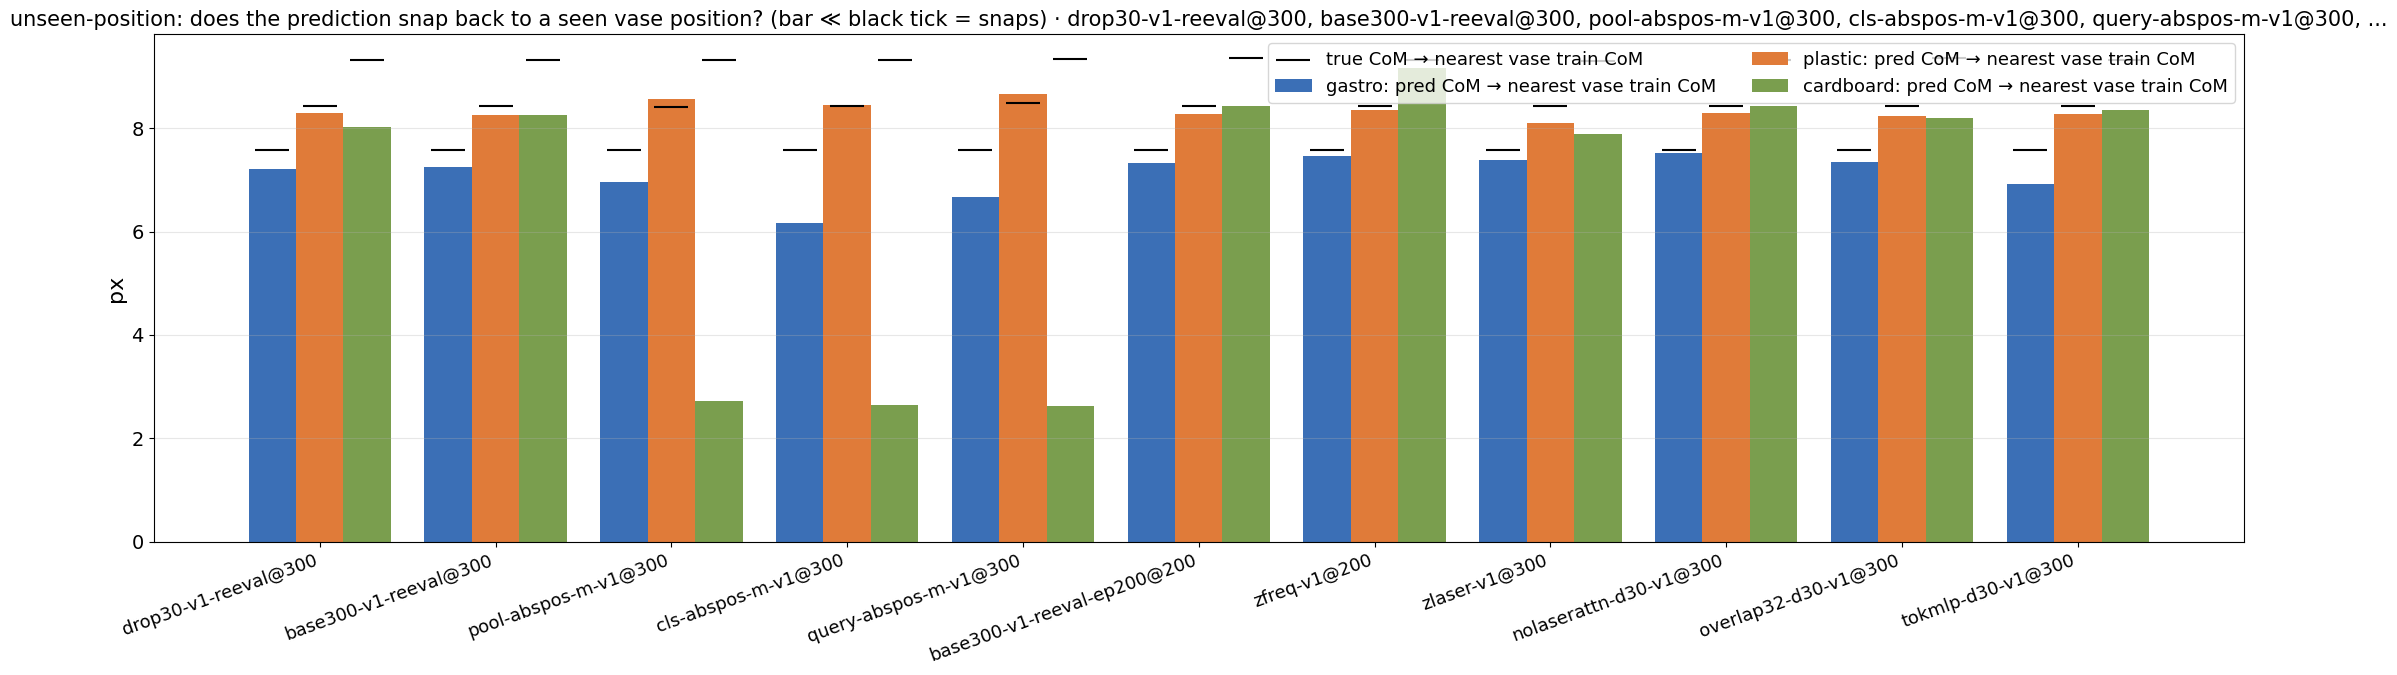

B check 2 · learned laser abspos (100 x d) after training


,laser abspos ‖·‖ per laser,init ‖·‖ (0.02√d),"R² abspos ~ quadratic(row, col)",top-2 PCs var %,freq abspos ‖·‖ per band,embed.bias ‖·‖ (content scale ref)
run@ep,,,,,,
pool-abspos-m-v1@300,0.420,0.400,0.057,4.798,0.413,1.004
cls-abspos-m-v1@300,0.414,0.400,0.054,4.556,0.408,1.002
query-abspos-m-v1@300,0.394,0.367,0.070,6.691,0.381,0.944


In [12]:
from score import sample_dir
from dataset import load_meta
RR, CC = np.mgrid[:64, :64]
def com(m): w = m.sum(); return np.array(((m * RR).sum() / w, (m * CC).sum() / w)) if w else np.array((np.nan, np.nan))
T1 = TR[DROP30]; T1 = T1[T1.n_obj == 1].drop_duplicates(["experiment", "position_id"]).copy()
T1["obj"] = ["+".join(load_meta(sample_dir(r.experiment, r.sample_id, r.position_id, r.speaker)).get("objects", [])) for r in T1.itertuples()]
T1["c"] = [com(truth(r.experiment, r.sample_id, r.position_id, r.speaker, 64, 64) > .5) for r in T1.itertuples()]
VASE = {e: np.stack(g[g.obj == "vase"].c) for e, g in T1.groupby("experiment")}
OTHER = {e: np.stack(g[g.obj != "vase"].c) for e, g in T1.groupby("experiment")}
rows = []
for r in [DROP30, BASE300] + GB["runs"] + [BASE300_200, ("zfreq-v1", 200), ("zlaser-v1", 300), ("nolaserattn-d30-v1", 300), ("overlap32-d30-v1", 300), ("tokmlp-d30-v1", 300)]:
    run, ep = r
    for pt in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/unseen-position/ep{ep:04d}-*.pt")):
        d = torch.load(pt, weights_only=False); P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            e = info["experiment"][i]
            ct, cp = com(truth(e, int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i]), 64, 64) > .5), com(P[i] > THR)
            if np.isnan(cp).any(): continue
            rows.append(dict(run=tag(r), box=pt.parent.parent.name, CoM_err=np.linalg.norm(cp - ct), true_to_vase=np.linalg.norm(VASE[e] - ct, axis=1).min(),
                             pred_to_vase=np.linalg.norm(VASE[e] - cp, axis=1).min(), true_to_other=np.linalg.norm(OTHER[e] - ct, axis=1).min()))
SNAP = pd.DataFrame(rows).groupby(["box", "run"], sort=False).mean().round(2)
print("B check 1 · unseen-position (vase in a vase-free train region): px distances, 64x64 grid")
display(SNAP.unstack(0).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0))
fig, ax = plt.subplots(figsize=(22, 7))
S = SNAP.reset_index(); runs = list(dict.fromkeys(S.run)); x = np.arange(len(runs)); w = 0.27
for j, b in enumerate(BOXES):
    s = S[S.box == b].set_index("run").reindex(runs)
    ax.bar(x + (j - 1) * w, s.pred_to_vase, w, color=BOXC[b], label=f"{b}: pred CoM → nearest vase train CoM")
    ax.scatter(x + (j - 1) * w, s.true_to_vase, marker="_", s=600, c="k", zorder=5, label="true CoM → nearest vase train CoM" if j == 0 else None)
ax.set_xticks(x, runs, rotation=20, ha="right"); ax.set_ylabel("px"); ax.grid(axis="y", alpha=.3); ax.legend(ncol=2)
ax.set_title("unseen-position: does the prediction snap back to a seen vase position? (bar ≪ black tick = snaps) · " + ", ".join(runs[:5]) + ", ...", fontsize=15)
plt.tight_layout(); plt.show()

rows = []
rc = np.stack(np.meshgrid(np.arange(10), np.arange(10), indexing="ij"), -1).reshape(100, 2).astype(float)
Xg = np.column_stack([np.ones(100), rc, rc ** 2, rc[:, :1] * rc[:, 1:]])
for run in ["pool-abspos-m-v1", "cls-abspos-m-v1", "query-abspos-m-v1"]:
    sd = torch.load(ROOT / f"runs/{run}/checkpoints/ep300-ba3000-rank0.pt", map_location="cpu", weights_only=False)["state"]["model"]
    a = sd["encoder.laser_enc.abspos"].float().numpy(); fa = sd["encoder.freq_enc.abspos"].float().numpy(); dd = a.shape[1]
    ac = a - a.mean(0)
    beta = np.linalg.lstsq(Xg, a, rcond=None)[0]; r2 = 1 - ((a - Xg @ beta) ** 2).sum() / (ac ** 2).sum()
    sv = np.linalg.svd(ac, compute_uv=False); ev = sv ** 2 / (sv ** 2).sum()
    rows.append({"run@ep": f"{run}@300", "laser abspos ‖·‖ per laser": np.linalg.norm(a, axis=1).mean(), "init ‖·‖ (0.02√d)": 0.02 * np.sqrt(dd),
                 "R² abspos ~ quadratic(row, col)": r2, "top-2 PCs var %": 100 * ev[:2].sum(), "freq abspos ‖·‖ per band": np.linalg.norm(fa, axis=1).mean(),
                 "embed.bias ‖·‖ (content scale ref)": float(sd["encoder.embed.bias"].norm())})
print("B check 2 · learned laser abspos (100 x d) after training")
pd.DataFrame(rows).set_index("run@ep").round(3)

### B · findings (pool / cls / query, all with abspos + wider model)
- **Where they fail: everywhere.**
  - ID −.14 to −.17 and OOD −.07.
  - Worst on **cardboard**: ID −.23 to −.26; unseen-position −.47 (misses go from 4 % to 81–89 %); cube-rotated −.40.
  - **multi-object** −.16 to −.19: objects hit fall from 80 % to 53–58 %, and objects ≥ 50 % covered from 48 % to 22 %.
  - ID misses go from 2 % to 12–14 %.
  - Masks are mushier (soft px 36–39 vs 29 %) and have more stray blobs (extra px 12–14 vs 3.5 %).
- **Where they succeed:** almost nowhere. plastic portable-charger gains +.06, and the unseen-speaker loss (−.03) is not significant.
- **Dynamics: they underfit and also generalize worse.**
  - They learn slower: ID .17–.24 at ep50 vs ~.40.
  - They end with a **lower** train-set fit, .77–.81 vs .82 (cardboard train .66–.72 vs .77).
  - The train − ID gap is larger, .26–.28 vs .15.
  - They are still creeping up (+.003 over ep250→300), but nowhere near enough to close a .15 gap.
  - They run 2.6× slower per sample (d400, mb64).
- **Mechanism (measured):**
  - **abspos never learned the grid.** After training, its norm is still at init (.42 vs .40), R² against a smooth (row, col) function is .057 (chance is about 5/99 ≈ .05), and the top 2 PCs hold 5 % of the variance.
  - So after a permutation-invariant pool or [cls], the model has no absolute laser identity. It has to infer position from content and **falls back on an object-conditional position prior.**
  - On cardboard unseen-position, the predicted vase lands **2.7 px from a seen vase position**, while the truth is 9.3 px away. The CoM error is 12 px vs 3 px for `per`.
  - This matches memory notes `project_cls_fail_t3` and `project_freqcls_nb117`: shared pooling drops slot identity. `per`'s 100 separate W_l are the slot identity.

## C · Tokenizer / architecture (vs drop30-v1-reeval@300)
Config: all three runs match drop30-v1 (drop .3 / .3, d256/h8, mb128, readout per, abspos 0) except for one flag each:
- `--band-overlap 32`: each band token sees 65 + 2·32 bins;
- `--tokenizer mlp`: the shared tokenizer is Linear → GELU → Linear (2d hidden) instead of one Linear;
- `--laser-layers 0`: no laser-laser attention, so the freq encoder feeds the per-laser readout directly.

This is the cleanest group.

C: paired Δ iou08 per slice (95% position-bootstrap CI)


n   base  run_iou  d_iou     lo     hi sig  d_biou biou_sig
run                    vs                   slice                                                                          
overlap32-d30-v1@300   drop30-v1-reeval@300 ID               2501  0.671    0.662 -0.009 -0.014 -0.005   -  -0.011        -
                                            OOD              1407  0.385    0.380 -0.005 -0.011 -0.000   -  -0.005         
                                            cardboard OOD     549  0.317    0.313 -0.004 -0.014  0.005      -0.005         
                                            cardboard ID      975  0.622    0.619 -0.002 -0.008  0.003      -0.003         
                                            gastro ID         653  0.671    0.649 -0.022 -0.033 -0.011   -  -0.024        -
                                            plastic ID        873  0.727    0.720 -0.007 -0.014 -0.001   -  -0.012        -
                                            multiple          310  0.349    0.327 -0.021 -0.034 -0.007   -  -0.018        -
                                            unseen-position   197  0.654    0.632 -0.022 -0.037 -0.007   -  -0.031        -
                                            unseen-speaker     85  0.465    0.438 -0.027 -0.060  0.005      -0.014         
                                            unseen-object     550  0.579    0.569 -0.010 -0.018 -0.003   -  -0.014        -
tokmlp-d30-v1@300      drop30-v1-reeval@300 ID               2501  0.671    0.651 -0.020 -0.025 -0.015   -  -0.025        -
                                            OOD              1407  0.385    0.383 -0.002 -0.008  0.004      -0.000         
                                            cardboard OOD     549  0.317    0.317 -0.000 -0.010  0.011      -0.000         
                                            cardboard ID      975  0.622    0.608 -0.014 -0.020 -0.008   -  -0.021        -
                                            gastro ID         653  0.671    0.624 -0.047 -0.059 -0.035   -  -0.053        -
                                            plastic ID        873  0.727    0.721 -0.006 -0.013 -0.000   -  -0.008         
                                            multiple          310  0.349    0.325 -0.023 -0.035 -0.011   -  -0.025        -
                                            unseen-position   197  0.654    0.620 -0.034 -0.053 -0.016   -  -0.041        -
                                            unseen-speaker     85  0.465    0.450 -0.015 -0.047  0.015      -0.008         
                                            unseen-object     550  0.579    0.582  0.003 -0.006  0.012       0.002         
nolaserattn-d30-v1@300 drop30-v1-reeval@300 ID               2501  0.671    0.665 -0.006 -0.010 -0.002   -  -0.011        -
                                            OOD              1407  0.385    0.378 -0.008 -0.013 -0.003   -  -0.008        -
                                            cardboard OOD     549  0.317    0.307 -0.010 -0.019 -0.001   -  -0.009        -
                                            cardboard ID      975  0.622    0.610 -0.012 -0.018 -0.006   -  -0.017        -
                                            gastro ID         653  0.671    0.669 -0.002 -0.013  0.008      -0.005         
                                            plastic ID        873  0.727    0.725 -0.002 -0.008  0.003      -0.007         
                                            multiple          310  0.349    0.348 -0.000 -0.013  0.014      -0.004         
                                            unseen-position   197  0.654    0.652 -0.002 -0.019  0.014      -0.022        -
                                            unseen-speaker     85  0.465    0.445 -0.020 -0.045  0.007      -0.023         
                                            unseen-object     550  0.579    0.570 -0.009 -0.016 -0.002   -  -0.010        -

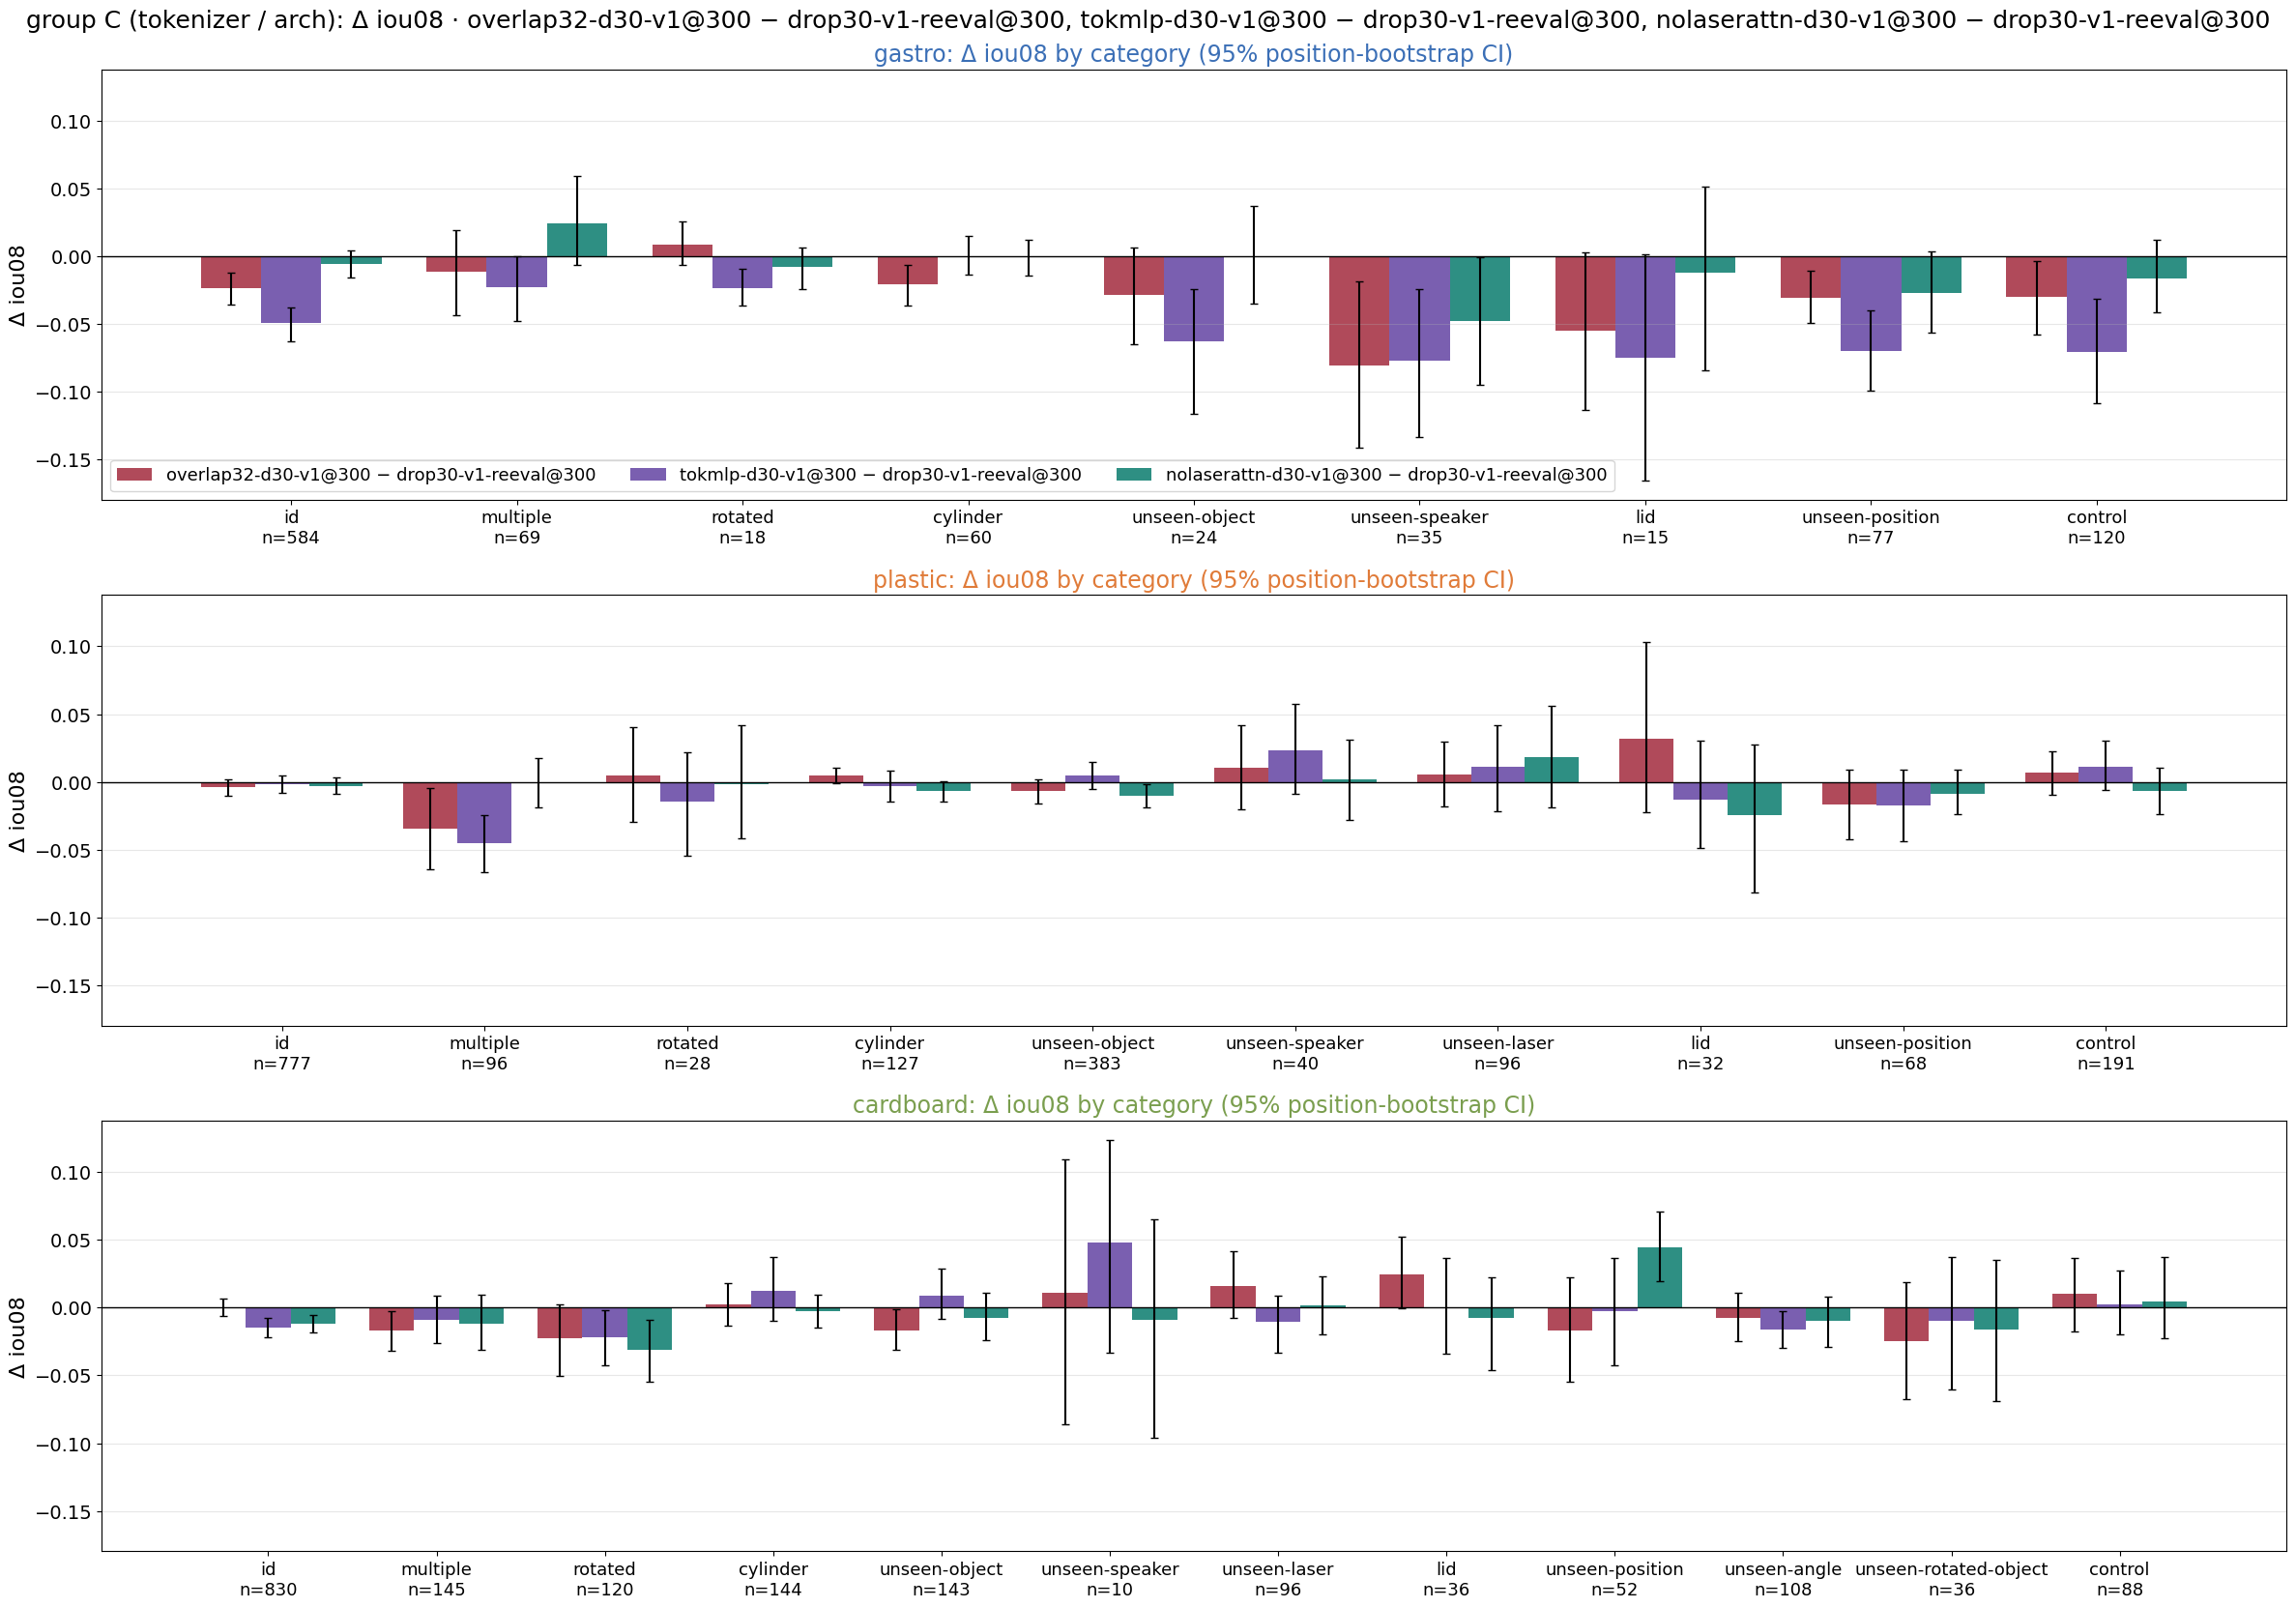

C: per split, robust wins and the 6 worst splits


cat    n   base      d     lo     hi  miss_b  miss_r
run                                            kind       split                                                                                                
overlap32-d30-v1@300 vs drop30-v1-reeval@300   robust win plastic/cylinder-1000g                      cylinder   32  0.326  0.013  0.005  0.020   0.000   0.000
                                               worst      gastro/cube-unseen-speaker-unseen     unseen-speaker   35  0.317 -0.081 -0.142 -0.019   0.114   0.286
                                                          gastro/cube                                       id  147  0.559 -0.071 -0.103 -0.040   0.027   0.061
                                                          gastro/cube-with-lid                             lid   15  0.150 -0.055 -0.112  0.003   0.533   0.733
                                                          gastro/cube-vase                            multiple   27  0.285 -0.052 -0.086 -0.019   0.000   0.074
                                                          plastic/two-cubes                           multiple   64  0.441 -0.044 -0.078 -0.013   0.000   0.000
                                                          cardboard/portable-charger             unseen-object   36  0.295 -0.041 -0.070 -0.018   0.167   0.306
tokmlp-d30-v1@300 vs drop30-v1-reeval@300      robust win plastic/portable-charger               unseen-object   40  0.307  0.050  0.010  0.098   0.100   0.025
                                                          cardboard/coffee-pot                   unseen-object   36  0.629  0.035  0.010  0.060   0.000   0.000
                                               worst      gastro/cube                                       id  147  0.559 -0.104 -0.139 -0.072   0.027   0.054
                                                          gastro/cube-unseen-speaker-unseen     unseen-speaker   35  0.317 -0.077 -0.135 -0.024   0.114   0.229
                                                          gastro/cube-with-lid                             lid   15  0.150 -0.075 -0.164  0.000   0.533   0.733
                                                          gastro/cube-unseen-speaker-baseline          control  105  0.555 -0.075 -0.115 -0.034   0.029   0.029
                                                          gastro/unseen-position               unseen-position   77  0.711 -0.070 -0.101 -0.042   0.000   0.013
                                                          gastro/coffee-pot                      unseen-object   24  0.644 -0.063 -0.112 -0.022   0.000   0.000
nolaserattn-d30-v1@300 vs drop30-v1-reeval@300 robust win cardboard/unseen-position            unseen-position   52  0.514  0.045  0.018  0.072   0.038   0.038
                                                          gastro/vase                                       id  135  0.736  0.028  0.007  0.048   0.007   0.007
                                               worst      gastro/cube-unseen-speaker-unseen     unseen-speaker   35  0.317 -0.048 -0.098  0.001   0.114   0.200
                                                          cardboard/soap-dispenser-rotated             rotated  100  0.559 -0.036 -0.065 -0.010   0.000   0.020
                                                          gastro/cube                                       id  147  0.559 -0.034 -0.064 -0.007   0.027   0.020
                                                          gastro/cylinder-100g                        cylinder    6  0.041 -0.027 -0.055  0.000   1.000   1.000
                                                          gastro/unseen-position               unseen-position   77  0.711 -0.027 -0.054  0.004   0.000   0.000
                                                          plastic/cube-with-lid                            lid   32  0.061 -0.024 -0.081  0.028   0.812   0.875

C: failure modes per slice


iou08   biou  area ratio (med)  under % (ar<.7)  over % (ar>1.5)  miss % (iou<.1)  multi: obj hit %  multi: obj ≥50% %  soft px %  extra px %
slice           run                                                                                                                                                                  
ID              drop30-v1-reeval@300    0.671  0.539             1.111            3.279            3.479            2.239            80.000             48.065     28.722       3.487
                overlap32-d30-v1@300    0.662  0.527             1.109            4.118            4.438            2.519            77.581             45.161     28.353       3.577
                tokmlp-d30-v1@300       0.651  0.514             1.124            3.758            5.798            2.839            75.484             48.065     29.087       4.216
                nolaserattn-d30-v1@300  0.665  0.528             1.123            3.159            4.798            2.279            80.484             50.323     28.585       3.486
OOD             drop30-v1-reeval@300    0.385  0.283             1.011           20.611           27.150           23.667               NaN                NaN     34.868      18.319
                overlap32-d30-v1@300    0.380  0.277             1.025           19.474           27.292           24.520               NaN                NaN     35.587      20.403
                tokmlp-d30-v1@300       0.383  0.282             1.024           18.124           27.221           23.952               NaN                NaN     36.370      20.860
                nolaserattn-d30-v1@300  0.378  0.274             1.073           17.626           29.211           25.231               NaN                NaN     35.993      21.342
cardboard ID    drop30-v1-reeval@300    0.622  0.472             1.124            4.000            3.385            3.385            76.207             46.552     33.764       5.656
                overlap32-d30-v1@300    0.619  0.470             1.128            4.308            4.718            3.897            72.069             44.483     32.913       5.631
                tokmlp-d30-v1@300       0.608  0.451             1.156            3.385            8.000            4.000            71.724             49.310     34.825       6.460
                nolaserattn-d30-v1@300  0.610  0.455             1.154            3.385            5.538            4.410            76.207             49.655     33.659       6.097
cardboard OOD   drop30-v1-reeval@300    0.317  0.234             0.978           33.515           12.933           38.616               NaN                NaN     46.499      27.295
                overlap32-d30-v1@300    0.313  0.229             1.000           32.240           15.118           39.162               NaN                NaN     48.839      30.399
                tokmlp-d30-v1@300       0.317  0.233             1.016           29.326           17.122           38.251               NaN                NaN     48.289      30.503
                nolaserattn-d30-v1@300  0.307  0.225             1.046           28.780           15.118           40.801               NaN                NaN     48.804      31.296
gastro ID       drop30-v1-reeval@300    0.671  0.563             1.108            3.522            2.757            3.369            73.188             29.710     29.049       3.767
                overlap32-d30-v1@300    0.649  0.539             1.100            4.594            3.828            3.828            76.812             25.362     29.573       4.228
                tokmlp-d30-v1@300       0.624  0.511             1.118            5.666            3.828            4.441            70.290             27.536     29.755       5.037
                nolaserattn-d30-v1@300  0.669  0.558             1.103            2.603            4.900            2.144            78.261             35.507     28.427       3.471
multiple        drop30-v1-reeval@300

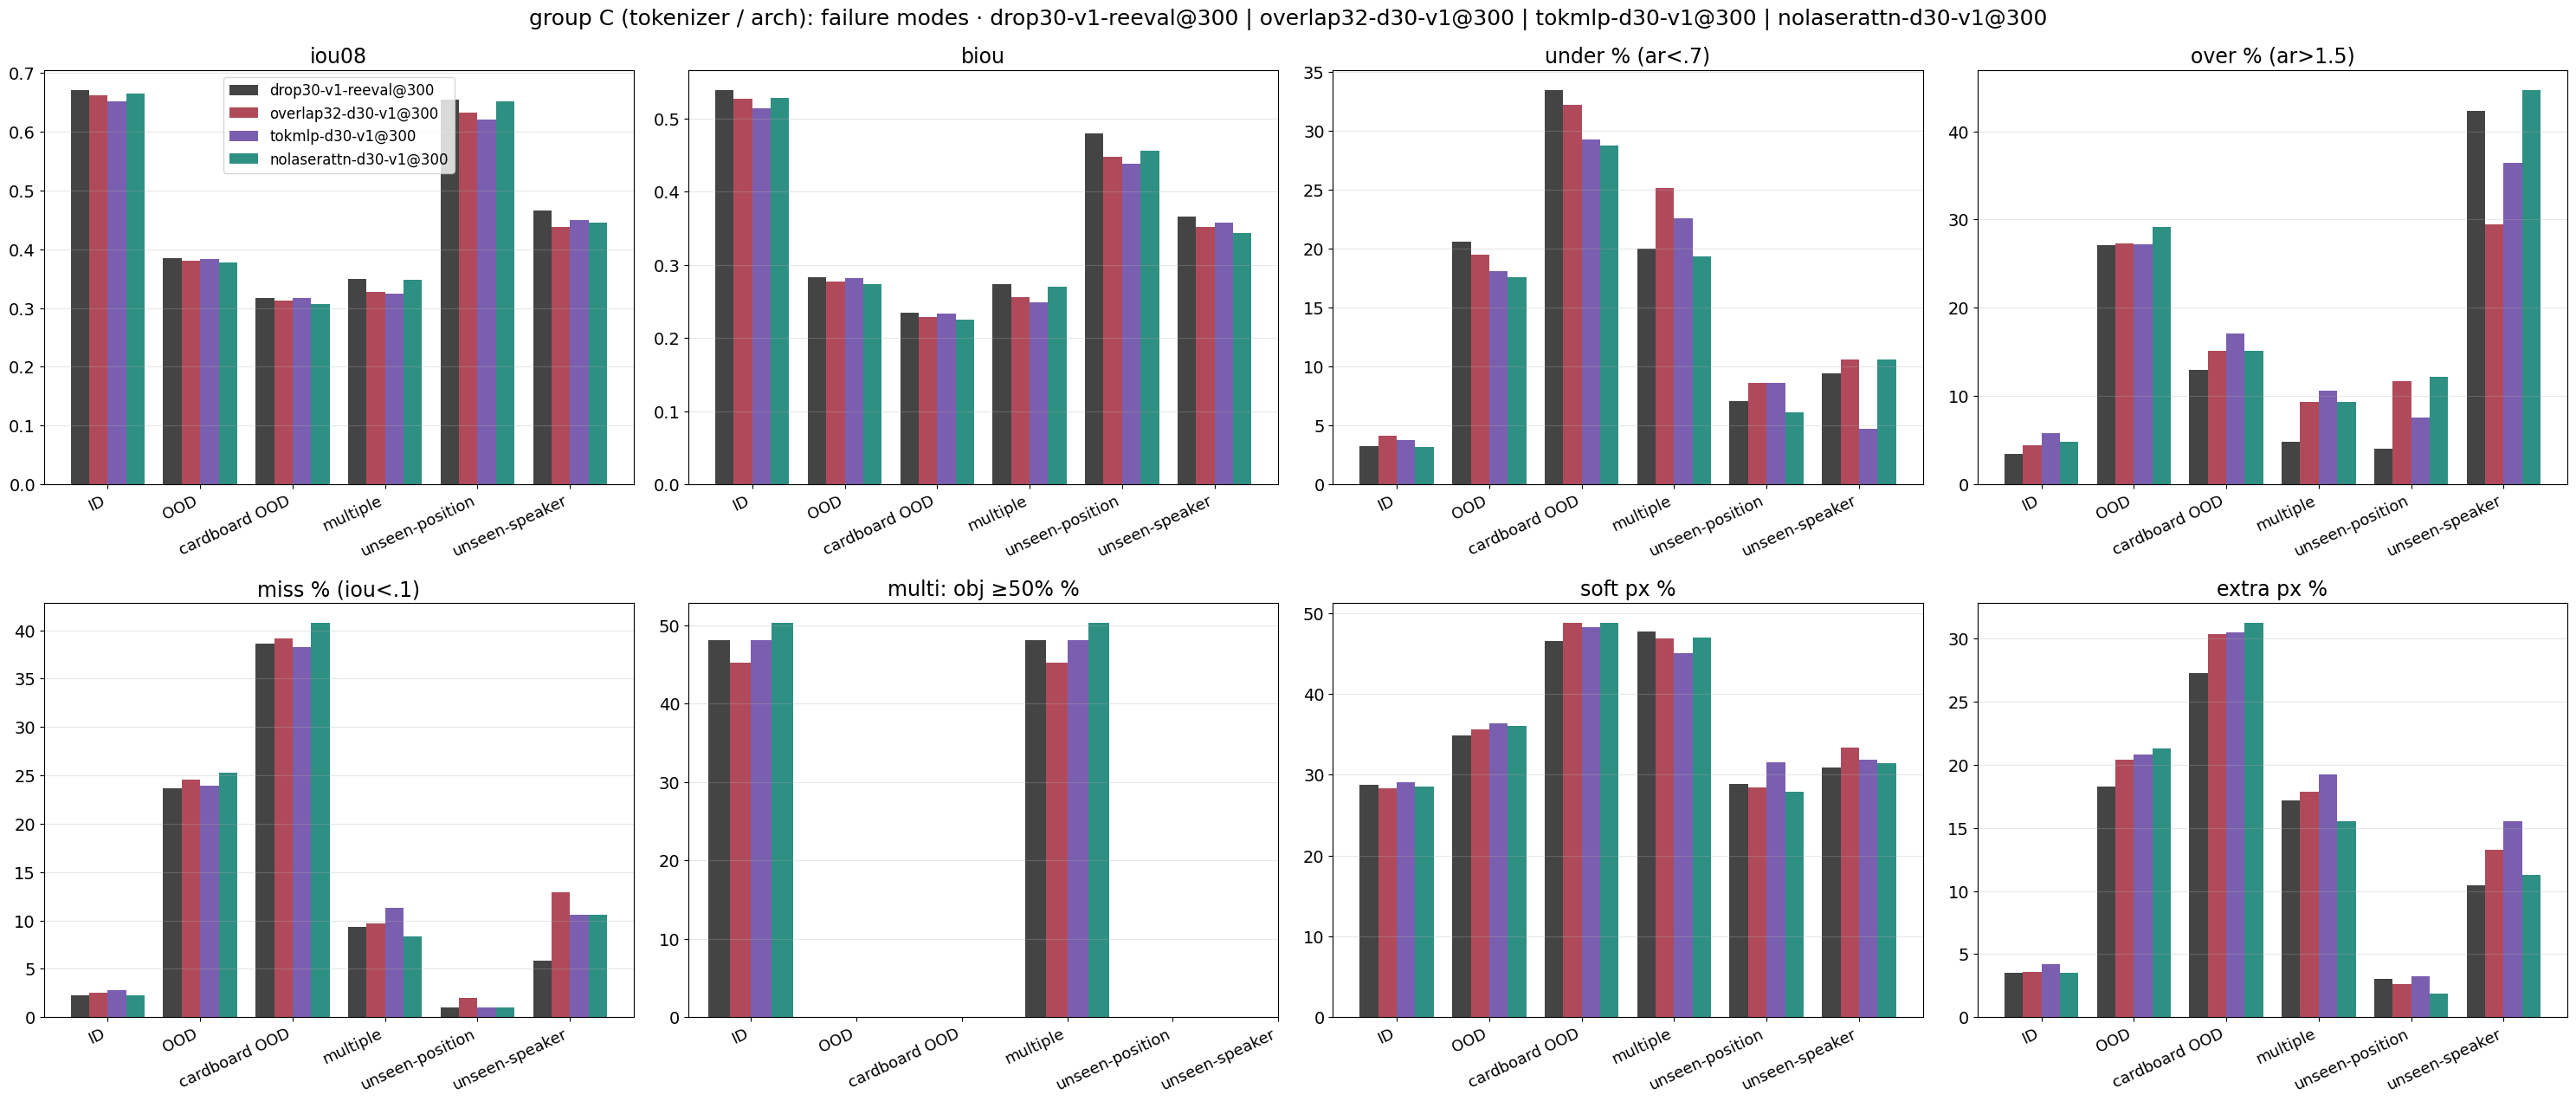

In [13]:
GC = GROUPS["C"]
print("C: paired Δ iou08 per slice (95% position-bootstrap CI)")
display(delta_table(GC))
cat_plot(GC)
print("C: per split, robust wins and the 6 worst splits")
display(split_table(GC))
print("C: failure modes per slice")
display(failure_table(GC))
failure_plot(GC)

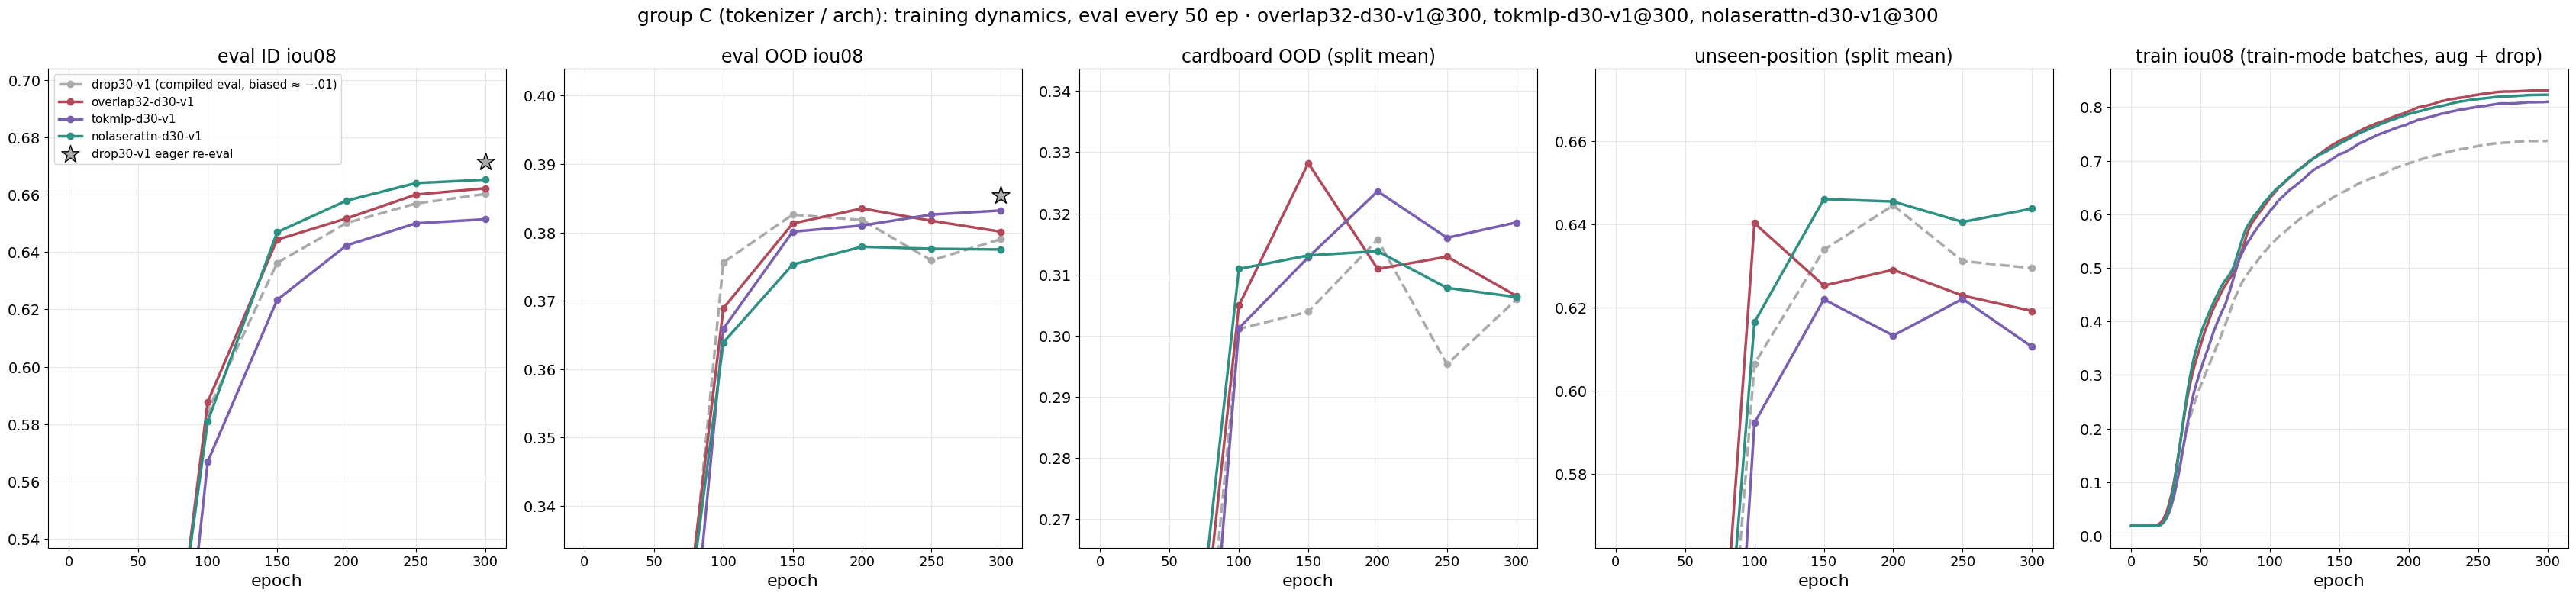

C: train-set fit vs eval


,train-set iou08,train gastro,train plastic,train cardboard,eval ID,eval OOD,gap train − ID
run,,,,,,,
drop30-v1-reeval@300,0.824,0.856,0.880,0.769,0.671,0.385,0.153
overlap32-d30-v1@300,0.832,0.862,0.885,0.780,0.662,0.380,0.170
tokmlp-d30-v1@300,0.811,0.851,0.882,0.740,0.651,0.383,0.159
nolaserattn-d30-v1@300,0.824,0.856,0.883,0.766,0.665,0.378,0.159


C: iou08 per slice over training (saved outputs, eager)


,ID,OOD,cardboard OOD,cardboard ID,gastro ID,plastic ID,multiple,unseen-position,unseen-speaker,unseen-object
run@ep,,,,,,,,,,
overlap32-d30-v1@50,0.394,0.283,0.172,0.275,0.411,0.513,0.204,0.433,0.271,0.495
overlap32-d30-v1@100,0.588,0.369,0.294,0.517,0.592,0.664,0.324,0.650,0.402,0.580
overlap32-d30-v1@150,0.644,0.381,0.322,0.589,0.637,0.712,0.341,0.638,0.425,0.575
overlap32-d30-v1@200,0.652,0.383,0.318,0.604,0.645,0.709,0.329,0.640,0.431,0.579
overlap32-d30-v1@250,0.660,0.382,0.317,0.617,0.646,0.718,0.326,0.636,0.437,0.571
overlap32-d30-v1@300,0.662,0.380,0.313,0.619,0.649,0.720,0.327,0.632,0.438,0.569
tokmlp-d30-v1@50,0.341,0.259,0.138,0.191,0.374,0.485,0.163,0.355,0.248,0.462
tokmlp-d30-v1@100,0.567,0.366,0.279,0.485,0.558,0.666,0.313,0.610,0.427,0.578
tokmlp-d30-v1@150,0.623,0.380,0.304,0.561,0.600,0.710,0.338,0.637,0.459,0.583


In [14]:
dyn_plot(GC, ["drop30-v1"])
print("C: train-set fit vs eval")
display(gap_table(GC))
rows = []
for r, _ in GC["runs"]:
    for ep in [50, 100, 150, 200, 250, 300]:
        S = EV.get((r, ep)); S = S if S is not None else per_sample(r, ep); EV[(r, ep)] = S
        rows.append({"run@ep": f"{r}@{ep}", **{k: S[m].iou.mean() for k, m in slices(S).items()}})
rows.append({"run@ep": tag(DROP30), **{k: EV[DROP30][m].iou.mean() for k, m in slices(EV[DROP30]).items()}})
print("C: iou08 per slice over training (saved outputs, eager)")
pd.DataFrame(rows).set_index("run@ep").round(3)

### C · mechanism checks (checkpoints + logs)
1. **Is the shared band tokenizer learned at all, and does overlap use its extra bins?** The check reads `encoder.embed.weight` from the ep300 checkpoints and compares it with a fresh `nn.Linear` init of the same shape: the per-bin column norm, the singular-value spectrum, and (for overlap) the share of weight, and of the top input directions, on the neighbours' bins. If the trained spectrum is indistinguishable from random, the tokenizer is a near-random, near-lossless projection: d = 256 ≥ 130 inputs for the baseline, 256 vs 258 for overlap. Then neither a better tokenizer (mlp) nor wider windows (overlap) has much to add, because all the learning happens downstream.
2. **Cost.** Parameter count from the checkpoint and the mean training throughput from the logs (samples / s).

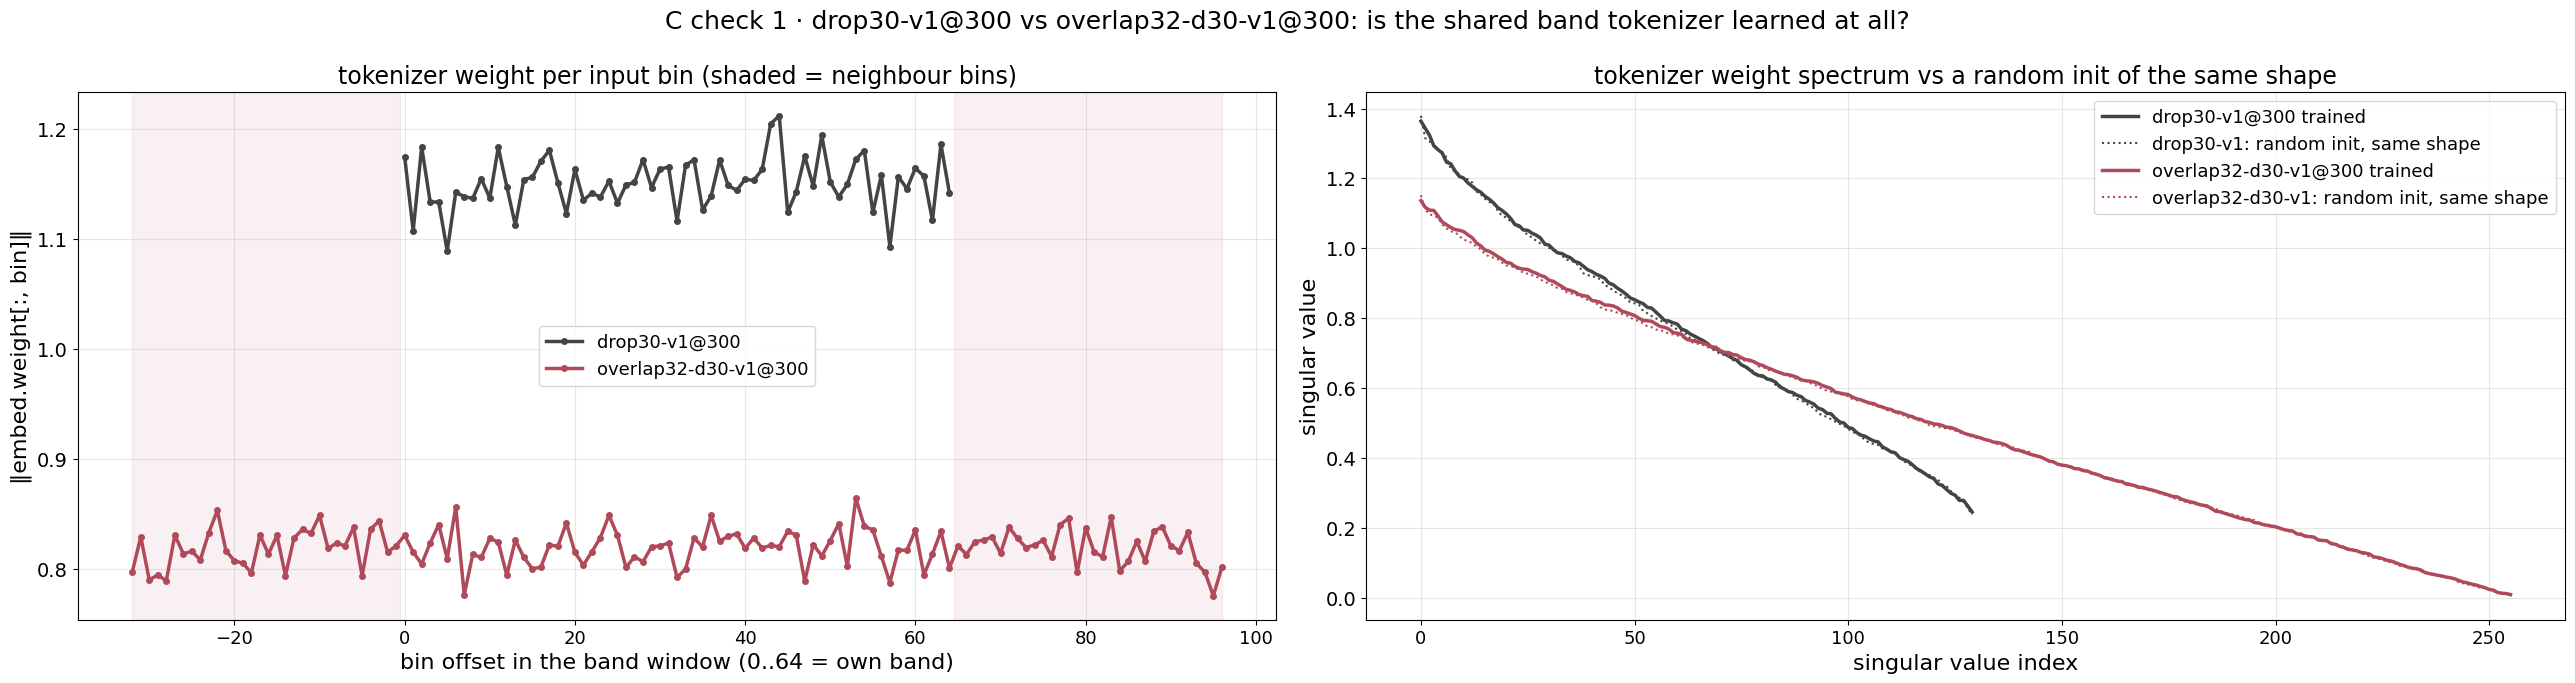

,‖w‖ per bin (mean),init ‖w‖ per bin (expected),top singular value,random-init top sv,# sv above the random-init max,neighbour-bin share of ‖w‖²,neighbour-bin share of top-8 input directions,share if unstructured
run@ep,,,,,,,,
drop30-v1@300,1.151,1.143,1.364,1.379,0,NaN,NaN,NaN
overlap32-d30-v1@300,0.819,0.812,1.136,1.152,0,0.496,0.486,0.496


C check 2 · cost (throughput = wall clock on a shared GPU, compare roughly)


,params (M),train samples/s (mean)
run@ep,,
drop30-v1@300,34.54,861.23
overlap32-d30-v1@300,34.57,607.31
tokmlp-d30-v1@300,34.70,595.93
nolaserattn-d30-v1@300,28.22,657.93
pool-abspos-m-v1@300,34.31,333.43
cls-abspos-m-v1@300,34.15,327.44
query-abspos-m-v1@300,35.37,329.33
base300-v1@300,34.54,859.43
zlaser-v1@300,34.54,598.17


In [15]:
def ckpt(run): return torch.load(ROOT / f"runs/{run}/checkpoints/ep300-ba3000-rank0.pt", map_location="cpu", weights_only=False)["state"]["model"]
fig, axs = plt.subplots(1, 2, figsize=(26, 7))
rows = []
for run, K, c in [("drop30-v1", 0, "#444444"), ("overlap32-d30-v1", 32, RUNC[0])]:
    w = ckpt(run)["encoder.embed.weight"].float().numpy()                        # (d, (65 + 2K) * 2), input index = bin * 2 + channel
    prof = np.linalg.norm(w.reshape(w.shape[0], -1, 2), axis=(0, 2))            # per bin
    axs[0].plot(np.arange(len(prof)) - K, prof, c=c, lw=2.5, marker="o", ms=4, label=f"{run}@300")
    init = np.random.default_rng(0).uniform(-1, 1, w.shape) / np.sqrt(w.shape[1])  # nn.Linear's kaiming-uniform init, same shape
    s, s0 = np.linalg.svd(w, compute_uv=False), np.linalg.svd(init, compute_uv=False)
    axs[1].plot(s, c=c, lw=2.5, label=f"{run}@300 trained"); axs[1].plot(s0, c=c, lw=1.5, ls=":", label=f"{run}: random init, same shape")
    row = {"run@ep": f"{run}@300", "‖w‖ per bin (mean)": prof.mean(), "init ‖w‖ per bin (expected)": np.linalg.norm(init.reshape(w.shape[0], -1, 2), axis=(0, 2)).mean(),
           "top singular value": s[0], "random-init top sv": s0[0], "# sv above the random-init max": int((s > s0.max()).sum())}
    if K:
        _, _, vt = np.linalg.svd(w, full_matrices=False)
        nb = np.isin(np.arange(w.shape[1]) // 2, np.r_[:K, K + 65:2 * K + 65])
        row |= {"neighbour-bin share of ‖w‖²": (w[:, nb] ** 2).sum() / (w ** 2).sum(), "neighbour-bin share of top-8 input directions": (vt[:8][:, nb] ** 2).sum() / 8,
                "share if unstructured": nb.mean()}
    rows.append(row)
axs[0].axvspan(-32, -0.5, color="#B04A5A", alpha=.08); axs[0].axvspan(64.5, 96, color="#B04A5A", alpha=.08)
axs[0].set(xlabel="bin offset in the band window (0..64 = own band)", ylabel="‖embed.weight[:, bin]‖", title="tokenizer weight per input bin (shaded = neighbour bins)")
axs[1].set(xlabel="singular value index", ylabel="singular value", title="tokenizer weight spectrum vs a random init of the same shape")
for a in axs: a.legend(); a.grid(alpha=.3)
fig.suptitle("C check 1 · drop30-v1@300 vs overlap32-d30-v1@300: is the shared band tokenizer learned at all?", fontsize=18); plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("run@ep").round(3))

rows = []
for run in ["drop30-v1", "overlap32-d30-v1", "tokmlp-d30-v1", "nolaserattn-d30-v1", "pool-abspos-m-v1", "cls-abspos-m-v1", "query-abspos-m-v1", "base300-v1", "zlaser-v1"]:
    sd = ckpt(run); L = LOG[run]
    rows.append({"run@ep": f"{run}@300", "params (M)": sum(v.numel() for k, v in sd.items() if v.is_floating_point() and "running" not in k) / 1e6,
                 "train samples/s (mean)": L[L.key == "throughput/samples_per_sec"].v.mean()})
print("C check 2 · cost (throughput = wall clock on a shared GPU, compare roughly)")
pd.DataFrame(rows).set_index("run@ep").round(2)

### C · findings
**Is the tokenizer learned?** In both drop30-v1 and overlap32, the trained `embed.weight` has the **same norm and singular spectrum as a random init**: column norm 1.151 vs 1.143, top singular value 1.36 vs 1.38, none above the random max. The shared linear tokenizer is effectively a fixed, near-lossless random projection, and all the learning happens downstream. That explains why both tokenizer changes did nothing useful.

**overlap32-d30-v1@300** (ID −.009, OOD −.005: a tie on pooled numbers)
- Losses are concentrated in gastro: ID −.022 (cube −.071), multiple −.021, unseen-position −.022.
- The only robust win is plastic cylinder-1000g (+.013).
- **The hoped-for "OOD win" is not there** (−.005, CI touches 0).
- The neighbour bins hold 49.6 % of the weight, exactly the unstructured share, so the extra input is simply mixed in.
- Slightly more overfit (train .832 vs .824) and 30 % slower.

**tokmlp-d30-v1@300** (ID −.020, OOD −.002)
- Nearly the whole loss is **gastro**: ID −.047, cube −.10, unseen-position −.07.
- plastic and cardboard OOD are unchanged.
- Small robust wins: plastic portable-charger +.05, cardboard coffee-pot +.035.
- **It learns slower early** (ID .34 at ep50 vs .39–.41 for the other C runs) and ends with a *lower* train-set fit (.811 vs .824), so it mildly underfits.
- It is flat over ep250→300, so more epochs at this LR will not fix it.

**nolaserattn-d30-v1@300** (ID −.006, OOD −.008: a tie, within the noise)
- Removing all 8 laser-attention blocks (18 % of the params, 34.5 M → 28.2 M) costs at most .012 on any slice (cardboard ID).
- Its worst splits are gastro unseen-speaker −.048 and cardboard soap-rotated −.036, both small or noisy.
- **Robust wins:** cardboard unseen-position +.045 and gastro vase +.028.
- Its CoM error on unseen-position is the lowest of the C runs (2.4 px vs 3.0 on cardboard).
- Laser-laser attention adds almost nothing on top of the per-laser readout, which is consistent with `project_cls_fail_t3` ("laser blocks add no linear info").

In [16]:
# cross-run summary: Δ iou08 per slice for every run vs its fair baseline; ★ = position CI excludes 0 and |Δ| ≥ .01
rows = {}
for G in GROUPS.values():
    for r in G["runs"]:
        b = base_of(G, r); M = paired(b, r)
        rows[f"{tag(r)} vs {tag(b)}"] = {k: (lambda d, lo, hi: f"{d:+.3f}{' ★' if (lo > 0 or hi < 0) and abs(d) >= .01 else ''}")(*ci(M[m])) for k, m in slices(M).items()}
SUMMARY = pd.DataFrame(rows).T
print("Δ iou08 per slice, every run vs its fair baseline (★ = 95% position CI excludes 0 and |Δ| ≥ .01)")
SUMMARY

Δ iou08 per slice, every run vs its fair baseline (★ = 95% position CI excludes 0 and |Δ| ≥ .01)


,ID,OOD,cardboard OOD,cardboard ID,gastro ID,plastic ID,multiple,unseen-position,unseen-speaker,unseen-object
zlaser-v1@300 vs base300-v1-reeval@300,-0.017 ★,-0.024 ★,-0.035 ★,-0.036 ★,+0.001,-0.008,+0.003,-0.016,-0.133 ★,-0.016 ★
zlaser-log-v1@300 vs base300-v1-reeval@300,-0.021 ★,-0.028 ★,-0.034 ★,-0.040 ★,+0.000,-0.014 ★,-0.003,+0.001,-0.130 ★,-0.018 ★
zfreq-v1@200 vs base300-v1-reeval-ep200@200,-0.013 ★,-0.010,-0.026 ★,-0.029 ★,-0.004,-0.001,-0.028 ★,+0.022 ★,+0.011,-0.005
pool-abspos-m-v1@300 vs drop30-v1-reeval@300,-0.160 ★,-0.071 ★,-0.149 ★,-0.244 ★,-0.141 ★,-0.081 ★,-0.178 ★,-0.221 ★,-0.040,-0.073 ★
cls-abspos-m-v1@300 vs drop30-v1-reeval@300,-0.143 ★,-0.071 ★,-0.146 ★,-0.234 ★,-0.107 ★,-0.067 ★,-0.163 ★,-0.228 ★,-0.028,-0.073 ★
query-abspos-m-v1@300 vs drop30-v1-reeval@300,-0.172 ★,-0.076 ★,-0.153 ★,-0.264 ★,-0.130 ★,-0.100 ★,-0.186 ★,-0.208 ★,-0.027,-0.082 ★
overlap32-d30-v1@300 vs drop30-v1-reeval@300,-0.009,-0.005,-0.004,-0.002,-0.022 ★,-0.007,-0.021 ★,-0.022 ★,-0.027,-0.010 ★
tokmlp-d30-v1@300 vs drop30-v1-reeval@300,-0.020 ★,-0.002,-0.000,-0.014 ★,-0.047 ★,-0.006,-0.023 ★,-0.034 ★,-0.015,+0.003
nolaserattn-d30-v1@300 vs drop30-v1-reeval@300,-0.006,-0.008,-0.010,-0.012 ★,-0.002,-0.002,-0.000,-0.002,-0.020,-0.009


## Verdict
**Noise scale.**
- Position-bootstrap 95 % CI half-widths are about ±.004 (ID) and ±.006 (OOD) pooled.
- A run's own ep250→ep300 Δ is ≤ .003.
- The nearest-neighbour config (drop .2 → .3) moves ID by −.009 and the per-split values by .012 on average.
- With no seed repeats, treat pooled |Δ| < ~.01 as a tie. Treat a single-split "win" on fewer than ~15 positions (e.g. cardboard unseen-position = 13 positions) as a lead, not a result.

| run | worth fixing? | why it lost | specific fix to try | expected upside | cost |
|---|---|---|---|---|---|
| zlaser-v1 | **no** | Up-weights noise bins 40–60×. Speaker-specific per-bin gain, so unseen speaker −.13. Overfits (train .90, gap .235) and under-paints cardboard. | none worth it. A soft std floor (e.g. ≥ .3 × median) would just slide back toward sample norm. | ≤ 0 pooled. Its only real win is gastro multi-object (+.05–.10), and that is gastro-only. | — |
| zlaser-log-v1 | **no** | same as zlaser; log-mag adds nothing | — | — | — |
| zfreq-v1 | **maybe** | Deletes the per-laser level map (position cue, R² up to .55). Loses cardboard and multiple. Also an unfinished run (ep200). | 1) Finish it: resume ep200 → ep300 for a fair final. 2) Better: sample norm **plus** a zfreq view, i.e. keep the level map and add the shape-normalised spectrum as a second input channel. | unseen-position +.02 (cardboard +.09), plastic unseen-speaker +.05. ID/cardboard deficit probably remains; the hybrid might keep both. | 1) ~⅓ run. 2) one 300-ep run + a small code change |
| pool-abspos-m-v1 | **no** | No slot identity: abspos stays at init. Snaps to object-position priors (cardboard unseen-pos −.47). Underfits and generalizes worse. | Only a fair re-test (d256, no abspos) would be worth it if pooling were the goal, but the −.14…−.17 gap is far too large to expect to close. | none | — |
| cls-abspos-m-v1 | **no** | same | same | none | — |
| query-abspos-m-v1 | **no** | same; 16 queries do not recover per-slot identity either | same | none | — |
| overlap32-d30-v1 | **no** | The tokenizer is a random-like projection, so the neighbour bins are just redundant input. Mild gastro losses; no OOD gain. | — | ~0 | — |
| tokmlp-d30-v1 | **no** | The tokenizer is not the bottleneck (the linear one never moves from init). The mlp learns slower and underfits gastro (−.047). | — | ~0 | — |
| nolaserattn-d30-v1 | **maybe (as a simplification)** | It didn't lose: a tie (−.006 / −.008). Laser attention contributes ≤ ~.01. | Drop the laser blocks and spend the 6 M params on more freq layers or a larger d, or keep 1–2 laser blocks. Run one seed repeat of nolaserattn alongside to confirm the tie. | 0 to +.01 pooled, plus the cardboard unseen-position lead (+.045) | one 300-ep run (cheaper than the baseline) |

**Splits where a run beats its baseline robustly, and what could be combined:**
- **cardboard unseen-position:** zfreq +.087 and nolaserattn +.045. Two independent changes both reduce the pull toward the seen-vase position prior. This is the most promising combination target: nolaserattn + a zfreq second channel.
- **plastic unseen-speaker:** zfreq +.053.
- **gastro multi-object** (cube-vase, two-cubes): zlaser +.05 to +.10. Gastro-only; it comes bundled with the unseen-speaker collapse, so it should not be adopted.
- **overlap's OOD:** not real (−.005).
- **zfreq's "flat OOD":** not a win; base@200 is also flat and higher.